# 08 — Kod Çözme (Decoding) Stratejileri: Model Sıradaki Token'ı Nasıl Seçer?

**Önkoşul:** 01-07. 06'da modelin her konumda bir **olasılık dağılımı** ürettiğini gördük; 07'de aynı modelleri hep `do_sample=False` ile (yani "en olası olanı al" diyerek) konuşturduk. Bu notebook'ta o küçük ayarın aslında **büyük bir karar** olduğunu göreceğiz: aynı model, aynı prompt, aynı ağırlıklar, ama farklı bir "seçme kuralı" ile bambaşka metinler çıkıyor. Bu notebook'ta **hiçbir şey eğitmiyoruz**: ağırlıklara dokunmadan sadece seçme kuralını değiştiriyoruz. Yine hazır modelleri kullanıyoruz; sıfırdan yazacağımız şeyler 3-10 satırlık çekirdekler (greedy, beam, top-k/top-p filtresi).

### Bu notebook'un 4 ana fikri

1. **Model token seçmez, olasılık verir.** Her adımda sözlükteki her token için bir olasılık çıkıyor (GPT-2'de 50.257 tane). "Decoding", bu olasılıklardan **birini seçme kuralı**; metin üretmek de bu seçimin tekrar tekrar yapılması.
2. **Greedy ve beam search "en olası"nın peşinde; ama en olası metin iyi metin değil.** Hızlı ve tekrarlanabilirler, fakat tekrar döngülerine düşüyorlar; insan yazısı ise en olası metin değil, sürprizlerle dolu.
3. **Sampling rastgelelik katar; temperature, top-k ve top-p bu rastgeleliği ayarlayan üç düğme.** Temperature dağılımın **şeklini**, top-k/top-p ise **kuyruğu** (binlerce düşük olasılıklı çöp token) kesiyor.
4. **RAG'e bağlantı:** Aynı bağlam, aynı okuyucu model; sadece sıcaklığı artırınca doğru cevap oranı çöküyor. Üstelik bağlamın yaptığı şey, dağılımı **sivrileştirmek** (belirsizliği düşürmek). "RAG neden bazen tutarsız/yaratıcı" sorusunun teknik cevabı burada.

Her bölümde önce **sezgi**, sonra **kod**, sonra **"Ne gördük?"** geliyor. "(İsteğe bağlı)" kısımları ilk okumada atlayabilirsin. Matematik hafif tutuldu.

### Kullanacağımız modeller (hepsi 06-07'den tanıdık)

| Model | Boyut | Ne için |
|---|---|---|
| `gpt2` | 124M, İngilizce | tüm decoding deneylerinin ana modeli (küçük, hızlı, hataları görünür) |
| `Qwen/Qwen2.5-0.5B` (base) | 494M, çok dilli | Türkçe deneyleri + üretilen metinlerin "hakemi" (aşağıda açıklanıyor) |
| `Qwen/Qwen2.5-0.5B-Instruct` | 494M | 8. bölümdeki RAG okuyucusu (07'deki aynı model) |

**Not (internet):** Üç model de 06-07'de indirildi; önbellekten gelmeli, yeni indirme yok.

**Not (kurulum):** `peft` bu notebook'ta gerekmiyor.

**Not (süre):** 8. bölümdeki RAG deneyi bizim 2 çekirdekli CPU'da ~10 dk sürdü; diğer bölümler dakikalar içinde bitiyor. Hücrelerin başında ne kadar süreceği yazıyor.

**Bellek notu:** Üç model de `float32`; toplam ~4,5 GB RAM. Belleğin dar ise `qwen_inst`'i sadece 8. bölüme gelince yükle (hücre o bölümün başında).

**Reprodüksiyon notu:** Üretim yardımcılarımız her çağrıda `torch.manual_seed(seed)` yapıyor. Yani bir sampling hücresini tek başına tekrar çalıştırırsan **aynı metni** alırsın; hücreleri sırasız çalıştırmak sonucu bozmaz (03'te yaşadığımız "paylaşılan rastgelelik" tuzağı burada yok). Farklı bir makinede tek tük token farkı olabilir; büyüklük sırası değişmemeli. Kullanılan global isimler: `gpt`, `tok_gpt`, `qwen_base`, `tok_q`, `qwen_inst`, `tok_qi`, `PROMPT`, `BILGILER`, `SONUC_KAL` ve fonksiyonlar (`kutu`, `ok_ciz`, `sonraki_dagilim`, `entropi`, `en_olasilar`, `uret`, `kume`, `tekrar_orani`, `cesitlilik`, `devam_nll`, `degerlendir`, `kosu`, `filtrele`, `rag_uret`, `dogru`). Egzersizlerde bunları **ezme**.

In [3]:
import time, math, os, gc, re, unicodedata
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import torch
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM
from dotenv import load_dotenv
load_dotenv()   # .env içindeki HF_TOKEN (varsa) indirmeleri hızlandırır

transformers.logging.set_verbosity_error()
transformers.logging.disable_progress_bar()
torch.set_grad_enabled(False)   # bu notebook'ta hiç eğitim yok: gradyan tutmaya gerek yok

print("torch", torch.__version__, "| transformers", transformers.__version__)

tok_gpt = AutoTokenizer.from_pretrained("gpt2")
gpt = AutoModelForCausalLM.from_pretrained("gpt2", dtype=torch.float32).eval()
tok_q = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B")
qwen_base = AutoModelForCausalLM.from_pretrained("Qwen/Qwen2.5-0.5B", dtype=torch.float32).eval()
print("yüklendi: gpt2 (124M) ve Qwen2.5-0.5B base (494M)")

torch 2.13.0 | transformers 5.17.0
yüklendi: gpt2 (124M) ve Qwen2.5-0.5B base (494M)


In [4]:
# ---- Şekil çizim yardımcıları (akış şemaları için) ----
def kutu(ax, x, y, w, h, metin, renk="#dbe9f6", kenar="#3b6ea5", fs=10, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=renk, ec=kenar, lw=1.6))
    ax.text(x + w/2, y + h/2, metin, ha="center", va="center", fontsize=fs,
            fontweight="bold" if bold else "normal")

def ok_ciz(ax, x1, y1, x2, y2, renk="#444", ls="-"):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", color=renk, lw=1.8, linestyle=ls))

In [5]:
# ---- Model yardımcıları ----
EOT = "<|endoftext|>"     # hem GPT-2 hem Qwen'de "metin başı/sonu" token'ı
PROMPT = "In a shocking finding, scientists discovered a herd of unicorns living in a remote valley in the Andes."   # GPT-2 makalesindeki prompt

def sonraki_dagilim(model, tok, prompt):
    """Prompt'tan sonra gelecek token için TÜM sözlük üzerinde olasılıklar (softmax çıktısı)."""
    ids = tok(prompt, return_tensors="pt")
    logits = model(**ids).logits[0, -1].float()
    return torch.softmax(logits, -1)

def entropi(p):
    """Dağılımın belirsizliği (nat). 0 = tamamen emin; ln(sözlük boyu) = tamamen şaşkın."""
    return -(p * torch.log(p.clamp_min(1e-12))).sum().item()

def en_olasilar(p, tok, k=10):
    v, i = torch.topk(p, k)
    return [(tok.decode(int(j)), float(x)) for x, j in zip(v, i)]

def uret(model, tok, prompt, n_token=60, n=1, seed=0, sample=False, T=1.0, top_k=0, top_p=1.0, rep=1.0, **kw):
    """Prompt'un devamını üretir. sample=False -> greedy (veya num_beams verirsen beam search).
    sample=True -> T / top_k / top_p ile sampling. Dönen: (metinler, token_id listeleri).
    Her çağrıda tohum sabitlenir: aynı çağrı = aynı sonuç. Varsayılan 'gizli' ayarlar (ör. Instruct'ın
    repetition_penalty=1.1'i) ezilsin diye hepsini AÇIKÇA veriyoruz."""
    torch.manual_seed(seed)
    ids = tok(prompt, return_tensors="pt")
    L = ids.input_ids.shape[1]
    ayar = dict(max_new_tokens=n_token, repetition_penalty=rep, pad_token_id=tok.eos_token_id, **kw)
    if sample:
        ayar.update(do_sample=True, temperature=T, top_k=top_k, top_p=top_p, num_return_sequences=n)
    else:
        ayar.update(do_sample=False, num_return_sequences=1)
    out = model.generate(**ids, **ayar)
    gen = [o[L:].tolist() for o in out]
    if not sample and n > 1:
        gen = gen * n                      # greedy/beam deterministik: n kopya
    return [tok.decode(g, skip_special_tokens=True) for g in gen], gen

def kume(model, tok, prompt, n=8, **kw):
    """n örnek üretir (greedy/beam ise aynı metnin n kopyası: çeşitlilik ölçümü için)."""
    return uret(model, tok, prompt, n=n, **kw)

def devam_nll(model, tok, prompt, devam_ids):
    """Prompt verilmişken devam token'larının toplam sürprizi (nat) ve token sayısı.
    Başa <|endoftext|> koyuyoruz (07'deki gibi). Sürpriz = -log(modelin o token'a verdiği olasılık)."""
    p = [tok.convert_tokens_to_ids(EOT)] + tok(prompt, add_special_tokens=False).input_ids
    x = torch.tensor([p + list(devam_ids)])
    logits = model(x).logits[0, len(p) - 1:-1].float()
    nll = torch.nn.functional.cross_entropy(logits, x[0, len(p):], reduction="none")
    return nll.sum().item(), len(devam_ids)

# ---- Üretilen metni değerlendirmek için 3 sayı ----
def tekrar_orani(metin, n=3):
    """Metindeki n-kelimelik dizilerin kaçı daha önce görülmüş bir dizinin tekrarı?
    0 = hiç tekrar yok, 1 = hep tekrar."""
    k = metin.split()
    g = [tuple(k[i:i+n]) for i in range(len(k) - n + 1)]
    return 0.0 if not g else 1 - len(set(g)) / len(g)

def cesitlilik(metinler, n=2):
    """Distinct-n: TÜM örneklerdeki n-kelimelik dizilerin kaçı birbirinden farklı?
    Örnekler birbirinin kopyasıysa düşük, hepsi farklıysa 1'e yakın."""
    g = []
    for m in metinler:
        k = m.split(); g += [tuple(k[i:i+n]) for i in range(len(k) - n + 1)]
    return len(set(g)) / max(len(g), 1)

def hakem_bpc(prompt, metinler, hakem=None, tok=None):
    """Üretilen metni, ÜRETEN modelden bağımsız bir 'hakem' modele (Qwen base) okutup bit/karakter ölçer.
    Düşük = hakem metni akıcı/olası buluyor; çok yüksek = saçma. (07'deki bit/karakter ölçüsü.)"""
    hakem = hakem or qwen_base; tok = tok or tok_q
    bpc = []
    for m in metinler:
        ids = tok(m, add_special_tokens=False).input_ids
        s, _ = devam_nll(hakem, tok, prompt, ids)
        bpc.append(s / math.log(2) / max(len(m), 1))
    return float(np.mean(bpc))

def degerlendir(prompt, metinler):
    return dict(tekrar=float(np.mean([tekrar_orani(m) for m in metinler])),
                cesit=cesitlilik(metinler), bpc=hakem_bpc(prompt, metinler))

SONUC_KAL = {}     # strateji adı -> {tekrar, cesit, bpc}; 3-5. bölümlerde dolacak, 5'in sonunda grafik çizeceğiz
def kosu(ad, prompt=PROMPT, n=8, n_token=60, **kw):
    """Bir decoding ayarıyla n örnek üret, değerlendir, SONUC_KAL'a kaydet."""
    metinler, ids = kume(gpt, tok_gpt, prompt, n=n, n_token=n_token, **kw)
    SONUC_KAL[ad] = degerlendir(prompt, metinler)
    return metinler, ids

## 1) Büyük resim: model token seçmez, olasılık verir

### Sezgi

06'da gördük: modelin son katmanı her konum için sözlük boyunca bir **skor** (logit) üretiyor, softmax bunu olasılığa çeviriyor. Yani model "sıradaki token `Paris`" demiyor; "`Paris` %46, `______` %10, `which` %5..." diyor. Bunu bir **oy pusulası** gibi düşün: sözlükteki her token için bir oy yüzdesi.

Metin üretmek için bu pusuladan **birini seçmemiz** gerekiyor. Seçilen token cümlenin sonuna eklenir, model yeni cümleyle tekrar çalışır, yeni bir pusula çıkar, yeniden seçeriz... Döngü bu. Döngünün tek "serbest" parçası **seçme kuralı**:

- **Greedy:** her kavşakta en kısa görünen yola sap.
- **Beam search:** tek yol yerine en iyi görünen k tane yarım rotayı aynı anda yürüt.
- **Sampling:** zar at; ama zar olasılıklara göre yüklü.

Önce döngünün şemasına bakalım.

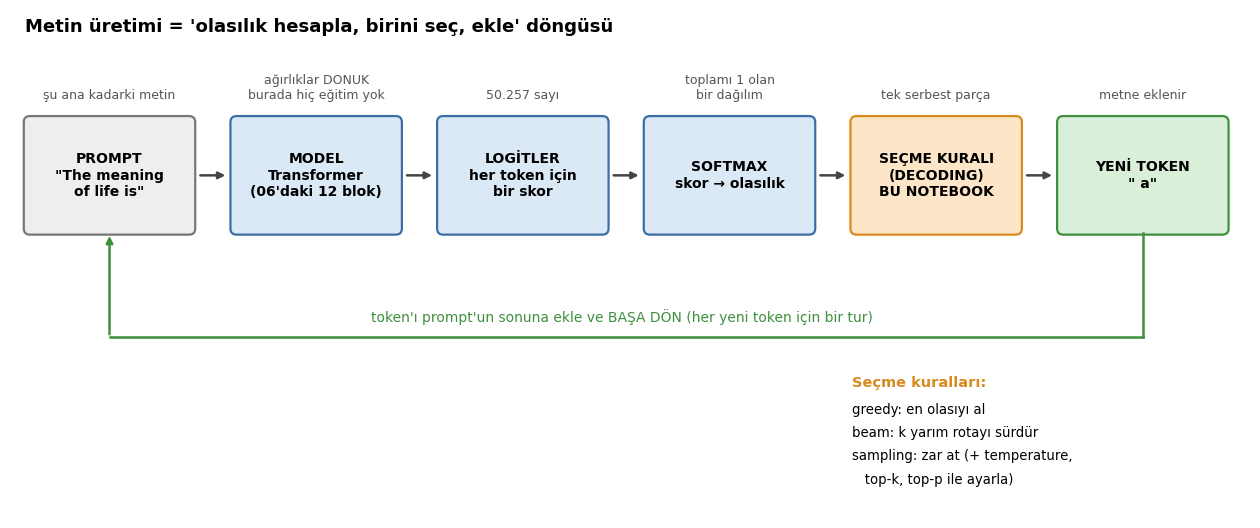

In [6]:
def draw_loop(save="decoding_loop.png"):
    V = gpt.config.vocab_size
    fig, ax = plt.subplots(figsize=(16, 6.6))
    ax.set_xlim(0, 16.2); ax.set_ylim(0, 6.6); ax.axis("off")
    ust = 3.7
    adimlar = [
        (0.2,  "PROMPT\n\"The meaning\nof life is\"", "#eeeeee", "#777777", "şu ana kadarki metin"),
        (2.9,  "MODEL\nTransformer\n(06'daki 12 blok)", "#dbe9f6", "#3b6ea5", "ağırlıklar DONUK\nburada hiç eğitim yok"),
        (5.6,  "LOGİTLER\nher token için\nbir skor", "#dbe9f6", "#3b6ea5", f"{V:,} sayı".replace(",", ".")),
        (8.3,  "SOFTMAX\nskor → olasılık", "#dbe9f6", "#3b6ea5", "toplamı 1 olan\nbir dağılım"),
        (11.0, "SEÇME KURALI\n(DECODING)\nBU NOTEBOOK", "#fde6c8", "#d98a1f", "tek serbest parça"),
        (13.7, "YENİ TOKEN\n\" a\"", "#d9efd9", "#3f8f3f", "metne eklenir"),
    ]
    for x, t, r, k, alt in adimlar:
        kutu(ax, x, ust, 2.2, 1.5, t, renk=r, kenar=k, fs=10, bold=True)
        ax.text(x + 1.1, ust + 1.7, alt, ha="center", va="bottom", fontsize=9, color="#555")
    for x in (2.45, 5.15, 7.85, 10.55, 13.25):
        ok_ciz(ax, x, ust + 0.75, x + 0.4, ust + 0.75)
    # geri dönüş oku
    ax.plot([14.8, 14.8], [ust, 2.35], color="#3f8f3f", lw=1.8)
    ax.plot([14.8, 1.3], [2.35, 2.35], color="#3f8f3f", lw=1.8)
    ok_ciz(ax, 1.3, 2.35, 1.3, ust, renk="#3f8f3f")
    ax.text(8.0, 2.55, "token'ı prompt'un sonuna ekle ve BAŞA DÖN (her yeni token için bir tur)", ha="center", fontsize=10, color="#3f8f3f")
    # seçme kuralı seçenekleri
    ax.text(11.0, 1.7, "Seçme kuralları:", fontsize=10.5, fontweight="bold", color="#d98a1f")
    ax.text(11.0, 1.35, "greedy: en olasıyı al", fontsize=9.5)
    ax.text(11.0, 1.05, "beam: k yarım rotayı sürdür", fontsize=9.5)
    ax.text(11.0, 0.75, "sampling: zar at (+ temperature,", fontsize=9.5)
    ax.text(11.0, 0.45, "   top-k, top-p ile ayarla)", fontsize=9.5)
    ax.text(0.2, 6.5, "Metin üretimi = 'olasılık hesapla, birini seç, ekle' döngüsü", fontsize=13, fontweight="bold", va="top")
    plt.savefig(save, dpi=130, bbox_inches="tight"); plt.show()
draw_loop()

**Ne gördük?**

- Döngüdeki **tek serbest parça turuncu kutu**. Model (donuk ağırlıklar), logitler ve softmax hangi stratejiyi seçersek seçelim aynı; greedy'den sampling'e geçince değişen tek şey bu kutu. Bu yüzden decoding, eğitim gerektirmeyen ama çıktıyı kökten değiştiren bir düğme.
- Döngü **her yeni token için baştan** dönüyor: 100 token'lık bir metin, modelin 100 kez çalışması demek (pratikte bir önbellek kullanılıyor ama mantık aynı). Bu yüzden strateji sadece kaliteyi değil **maliyeti** de belirliyor; örneğin beam search k kat daha çok hesap isteyecek.

### Pusulanın şekli her yerde aynı değil

Aynı modelin farklı prompt'larda, ve farklı modellerin aynı prompt'ta ürettiği dağılıma bakalım. Her grafik, sıradaki token için **en olası 10 adayı** gösteriyor. Başlıktaki **entropi**, dağılımın belirsizliğinin tek sayılık özeti: 0 = model tamamen emin, büyük = model çok şaşkın. (Birazdan bu sayıyı çok kullanacağız.)

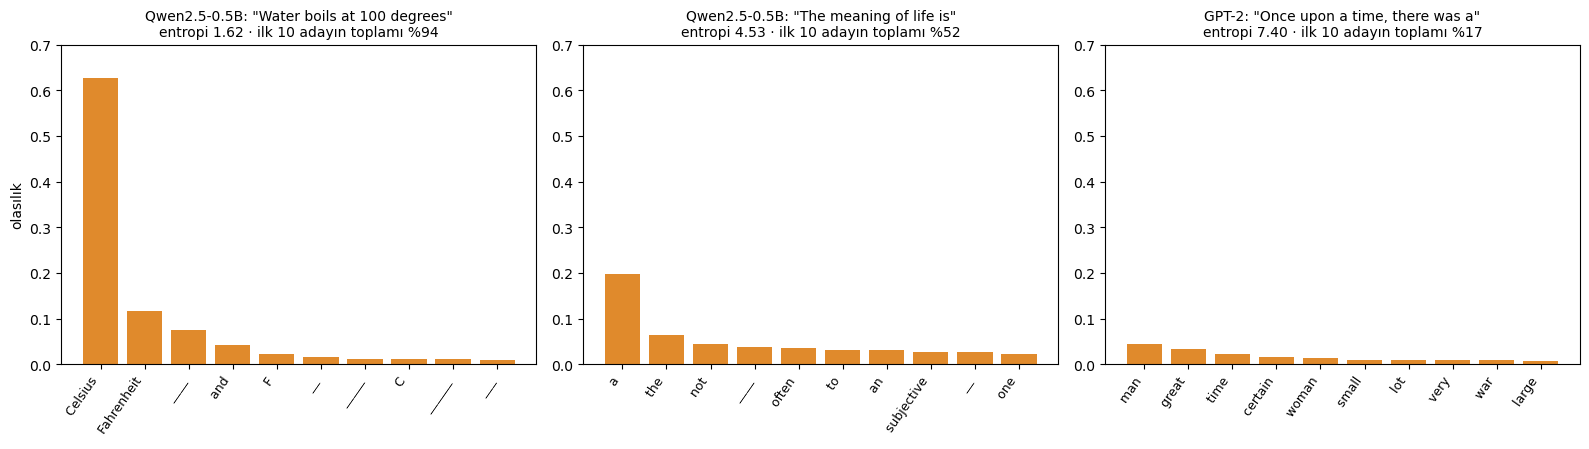

In [7]:
vitrin = [
    (qwen_base, tok_q,   "Water boils at 100 degrees",       "Qwen2.5-0.5B"),
    (qwen_base, tok_q,   "The meaning of life is",           "Qwen2.5-0.5B"),
    (gpt,       tok_gpt, "Once upon a time, there was a",    "GPT-2"),
]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (m, t, pr, ad) in zip(axes, vitrin):
    p = sonraki_dagilim(m, t, pr)
    top = en_olasilar(p, t, 10)
    ax.bar(range(10), [x for _, x in top], color="#e08a2c")
    ax.set_xticks(range(10)); ax.set_xticklabels([repr(s)[1:-1] for s, _ in top], rotation=55, ha="right", fontsize=9)
    ax.set_title(f"{ad}: \"{pr}\"\nentropi {entropi(p):.2f} · ilk 10 adayın toplamı %{100*sum(x for _, x in top):.0f}", fontsize=10)
    ax.set_ylim(0, 0.7)
axes[0].set_ylabel("olasılık")
plt.tight_layout(); plt.savefig("next_token_distribution.png", dpi=130); plt.show()

**Ne gördük?**

- **Sol (Qwen, "Water boils at 100 degrees"):** sivri dağılım. `Celsius` tek başına %63, ilk 10 aday toplam %94, entropi 1.62. (Boşluk gibi görünen `______` adayları, Qwen'in internetteki alıştırma/boşluk doldurma metinlerini de görmüş olmasından.)
- **Orta (Qwen, "The meaning of life is"):** orta. En olası `a` %20, ilk 10 aday toplam %52, entropi 4.53. Burada gerçekten birçok makul devam var.
- **Sağ (GPT-2, "Once upon a time, there was a"):** yayvan. En olası `man` sadece %4, ilk 10 adayın toplamı **%17**, entropi 7.40. Kütlenin %83'ü sayısız başka token'a dağılmış.
- Yani dağılımın şekli **prompt'a ve modele** göre çok değişiyor. "Her zaman en iyi 50'yi tut" ya da "her zaman 0.7 sıcaklık" gibi tek bir ayar bu üç durumun hepsine aynı iyi davranmaz. Top-p fikri tam bu gözlemden çıkıyor (5. bölüm).

### Greedy'nin çekirdeği: 3 satır

Seçme kuralını en sade haliyle yazalım: her turda modeli çalıştır, en yüksek skoru seç, ekle. Sonra `generate(do_sample=False)` ile aynı sonucu verdiğini kontrol edelim; böylece 07'de `do_sample=False` yazarken aslında ne dediğimizi biliyoruz.

In [8]:
def greedy_elle(model, ids, n):
    for _ in range(n):
        logits = model(ids).logits[0, -1]                    # 1) model: sonraki token için skorlar
        sonraki = logits.argmax()                            # 2) SEÇME KURALI: en yüksek skor
        ids = torch.cat([ids, sonraki.view(1, 1)], dim=1)    # 3) ekle ve başa dön
    return ids

x = tok_gpt("The meaning of life is", return_tensors="pt").input_ids
a = greedy_elle(gpt, x, 20)
b = gpt.generate(x, max_new_tokens=20, do_sample=False, pad_token_id=tok_gpt.eos_token_id)
print("elle yazılan == generate(do_sample=False):", torch.equal(a, b))
print(repr(tok_gpt.decode(a[0])))

elle yazılan == generate(do_sample=False): True
'The meaning of life is not the same as the meaning of death.\n\nThe meaning of life is not the same as'


**Ne gördük?**

- Elle yazdığımız 3 satırlık döngü `generate(do_sample=False)` ile **birebir aynı** (`True`). Yani 07'de `do_sample=False` yazarken aslında tam olarak bunu yapıyorduk.
- Daha 20 token'da bile bir sorunun işareti var: "The meaning of life is not the same as the meaning of death.", sonra aynı cümle `The meaning of life is not the same as` diye yeniden başlıyor. Bir sonraki bölümün konusu bu.

## 2) Greedy: her adımda en olasıyı al

### Sezgi

Greedy en basit kural: `argmax`. Hızlı, **deterministik** (aynı prompt → hep aynı cevap), RAG'de "cevap her seferinde aynı olsun" istediğimizde cazip. İki bilinen sorunu var:

1. **Yerel en iyi, toplamda en iyi olmayabilir.** Şimdi en olası kelimeyi seçmek, üç kelime sonra modeli çıkmaza sokabilir (bunu 3. bölümde beam search ile deneyeceğiz).
2. **Tekrar döngüsü.** Model bir cümleyi tekrar etmeye başlarsa, tekrar etmek bir sonraki adımda **daha da olası** hale geliyor ve model bir daha çıkamıyor (Xu ve ark. 2022 buna "self-reinforcement" diyor).

İkincisini 100 token'lık bir greedy üretimde görelim. Her token için "model bu token'ı ne kadar olası bulmuştu?" eğrisini çizeceğiz; **kırmızı noktalar** daha önce görülmüş bir 4-token'lık diziyi tekrarlayan token'lar.

The researchers found that the animals were able to survive in a climate that was warmer than the average for the region.

"The animals were able to survive in a climate that was warmer than the average for the region," said lead author Dr. David H. Hirsch, a professor of ecology and evolutionary biology at the University of California, Berkeley.

The researchers found that the animals were able to survive in a climate that was warmer than the average for the region.

tekrar oranı (3-kelimelik dizilerin kaçı tekrar): 0.43


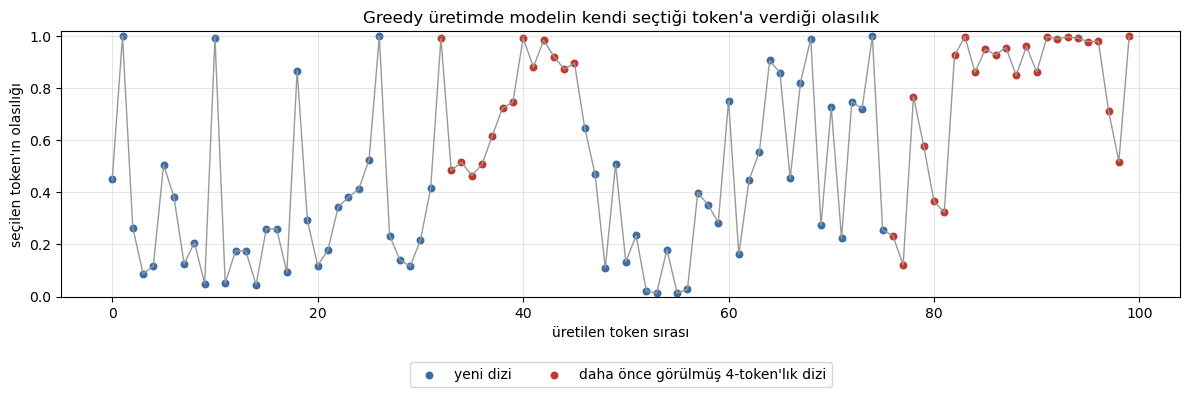

ilk tekrar token 32'de başlıyor | tekrar öncesi ort. olasılık 0.33, tekrar sonrası 0.63


In [9]:
metinler, ids = uret(gpt, tok_gpt, PROMPT, n_token=100)
devam = metinler[0]
print(devam.strip()[:700])
print(f"\ntekrar oranı (3-kelimelik dizilerin kaçı tekrar): {tekrar_orani(devam):.2f}")

# modelin her token için verdiği olasılık: üretilen diziyi bir kez daha modele verip okuyoruz
prompt_ids = tok_gpt(PROMPT).input_ids
tam = torch.tensor([prompt_ids + ids[0]])
p_tum = torch.softmax(gpt(tam).logits[0, len(prompt_ids) - 1:-1].float(), -1)
p_sec = p_tum[torch.arange(len(ids[0])), torch.tensor(ids[0])].numpy()
tekrar_mi = np.zeros(len(ids[0]), bool); goruldu = set()
for i in range(3, len(ids[0])):
    anahtar = tuple(ids[0][i-3:i+1])
    tekrar_mi[i] = anahtar in goruldu; goruldu.add(anahtar)

plt.figure(figsize=(12, 4.2))
plt.plot(p_sec, color="#999999", lw=1)
plt.scatter(np.arange(len(p_sec))[~tekrar_mi], p_sec[~tekrar_mi], color="#3b6ea5", s=22, label="yeni dizi")
plt.scatter(np.arange(len(p_sec))[tekrar_mi],  p_sec[tekrar_mi],  color="#c0392b", s=22, label="daha önce görülmüş 4-token'lık dizi")
plt.xlabel("üretilen token sırası"); plt.ylabel("seçilen token'ın olasılığı"); plt.ylim(0, 1.02)
plt.title("Greedy üretimde modelin kendi seçtiği token'a verdiği olasılık"); plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("greedy_repetition_curve.png", dpi=130); plt.show()
ilk_tekrar = int(np.argmax(tekrar_mi))
print(f"ilk tekrar token {ilk_tekrar}'de başlıyor | tekrar öncesi ort. olasılık {p_sec[:ilk_tekrar].mean():.2f}, tekrar sonrası {p_sec[ilk_tekrar:].mean():.2f}")

**Ne gördük?**

- Metin ilk cümlelerde akıcı ve mantıklı, sonra **aynı cümleyi baştan yazıyor** ("The researchers found that the animals were able to survive in a climate that was warmer than the average for the region." üç kez). Tekrar oranı 0.43: 3-kelimelik dizilerin %43'ü daha önce görülmüş.
- Grafik mekanizmayı gösteriyor. İlk tekrar 32. token'da başlıyor. Tekrardan **önce** model seçtiği token'a ortalama %33 olasılık veriyordu; tekrar **başladıktan sonra** ortalama %63. Son ~20 token'da kırmızı noktalar tavana yapışmış (olasılık ~1.0): model kendi cümlesini kopyalarken artık hiç şaşırmıyor. Kopyaladıkça bir sonraki kopyayı yazmak daha olası hale geliyor; bu **kısır döngü**.
- Greedy'nin güçlü yanı da bunun tersi: kısa, olgusal cevaplarda (8. bölümdeki RAG cevapları gibi) hızlı ve tekrarlanabilir. 07'de en fazla 28-40 token ürettiğimiz için bu sorunu hiç görmedik.

## 3) Beam search: tek yol yerine k yol

### Sezgi

Greedy her kavşakta "şimdilik en iyi"yi seçiyordu. Beam search her adımda **k tane yarım cümleyi** (beam) elinde tutuyor: her birini bir token uzatıyor, ortaya çıkan k × (sözlük) adayın arasından **toplam olasılığı en yüksek k tanesini** tutuyor ve devam ediyor. Sonunda toplam olasılığı en yüksek cümle kazanıyor.

Navigasyon benzetmesi: greedy her kavşakta o an en kısa görünen sokağa sapar. Beam, k tane rotayı aynı anda yürütür ve sonunda **toplamda** en kısa olanı seçer. Böylece "şimdi cazip ama çıkmaz" yollara daha az kanar.

(Toplam olasılık = olasılıkların çarpımı; bilgisayar bunu logaritmaların toplamı olarak tutar: **log-olasılık**. 0'a yakın = daha olası. Detay isteğe bağlı.)

### Çekirdeği elle yazalım (~10 satır)

Sonra Hugging Face'in `num_beams` ayarıyla **aynı skorları** verdiğini göstereceğiz.

In [10]:
def beam_elle(model, ids, n, k):
    beams = [(0.0, ids[0].tolist())]                         # (toplam log-olasılık, token listesi)
    for _ in range(n):
        adaylar = []
        for skor, dizi in beams:
            lp = torch.log_softmax(model(torch.tensor([dizi])).logits[0, -1].float(), -1)
            v, i = torch.topk(lp, k)                         # her beam'in en iyi k devamı
            adaylar += [(skor + float(a), dizi + [int(b)]) for a, b in zip(v, i)]
        beams = sorted(adaylar, key=lambda t: -t[0])[:k]     # k*k aday içinden en iyi k tanesi
    return beams

x = tok_gpt("The meaning of life is", return_tensors="pt").input_ids
t0 = time.time(); elle = beam_elle(gpt, x, 20, 4); print(f"elle beam (k=4, 20 token): {time.time()-t0:.1f} sn\n")
hf = gpt.generate(x, max_new_tokens=20, num_beams=4, num_return_sequences=4, do_sample=False, length_penalty=0.0,
                  early_stopping=False, pad_token_id=tok_gpt.eos_token_id, output_scores=True, return_dict_in_generate=True)
print(f"{'elle skor':>10} {'HF skor':>9}   metin")
for (s, d), s_hf in zip(elle, hf.sequences_scores):
    print(f"{s:>10.2f} {s_hf.item():>9.2f}   {tok_gpt.decode(d)!r}")
print("\nen iyi beam aynı mı:", elle[0][1] == hf.sequences[0].tolist())

elle beam (k=4, 20 token): 1.4 sn

 elle skor   HF skor   metin
    -19.34    -19.34   'The meaning of life is not the same as the meaning of death. The meaning of life is not the same as the meaning'
    -21.08    -21.08   'The meaning of life is not the same as the meaning of death. The meaning of life is the same as the meaning of'
    -21.19    -21.19   'The meaning of life is not the same as the meaning of death. The meaning of life is not the same as death.'
    -21.19    -21.19   'The meaning of life is not the same as the meaning of death. The meaning of death is not the same as the meaning'

en iyi beam aynı mı: True


**Ne gördük?**

- Elle yazdığımız 10 satırın skorları Hugging Face'in `num_beams=4` sonucuyla **birebir aynı** (−19.34, −21.08, −21.19, −21.19) ve en iyi beam aynı cümle. `num_beams` bu döngünün optimize edilmiş hali.
- İlginç olan en olası cümlenin kendisi: "The meaning of life is not the same as the meaning of death. The meaning of life is not the same as the meaning". Modelin gözünde **en olası** cümle bile kendini tekrar ediyor.
- Maliyet: 20 token için 4 beam'in her adımda ayrı ayrı çalıştırılması ~5 sn sürdü (bizim kodda önbellek yok; yine de beam'in greedy'den ~k kat pahalı olduğu fikri geçerli).

### Beam daha "iyi" cümle mi buluyor?

Aynı unicorn prompt'u, 60 token. `k=1` greedy'dir; k büyüdükçe beam daha çok rota deniyor. İki şeye bakıyoruz: modelin gözünde **toplam olasılık** (yüksek = model bu cümleyi daha olası buluyor) ve **tekrar oranı**.

In [11]:
print(f"{'k':>3} {'toplam log-olasılık':>20} {'tekrar oranı':>13}   ilk 100 karakter")
for k in [1, 3, 5, 10]:
    ad = "greedy" if k == 1 else f"beam {k}"
    ayar = {} if k == 1 else dict(num_beams=k, length_penalty=0.0, early_stopping=False)
    metinler, ids = kosu(ad, n=8, n_token=60, **ayar)
    s, _ = devam_nll(gpt, tok_gpt, PROMPT, ids[0])
    print(f"{k:>3} {-s:>20.1f} {tekrar_orani(metinler[0]):>13.2f}   {metinler[0].strip()[:100]!r}")

  k  toplam log-olasılık  tekrar oranı   ilk 100 karakter
  1                -79.0          0.30   'The researchers found that the animals were able to survive in a climate that was warmer than the av'
  3                -59.7          0.21   'The researchers, from the University of California, San Diego, and the University of California, San'
  5                -61.8          0.05   'The researchers, from the University of California, San Diego, and the University of California, San'
 10                -59.5          0.21   'The researchers, from the University of California, San Diego, and the University of California, San'


**Ne gördük?**

- **Beam, greedy'nin bulamadığı çok daha olası bir cümle buldu:** toplam log-olasılık greedy'de −79.0, beam'lerde ≈ −60. "Yerel en iyi toplamda en iyi olmayabilir" iddiası doğrulandı: greedy ilk kelimeleri seçerken çıkmaza giden bir yola girmiş.
- **Ama beam monoton iyileşmiyor:** k=5 (−61.8) k=3'ten (−59.7) daha kötü. Beam search kesin çözüm değil, budamalı bir arama; k'yı büyütmek skoru her zaman iyileştirmiyor.
- **Daha olası ≠ daha iyi.** Beam metinleri "The researchers, from the University of California, San Diego, and the University of California, San..." gibi kendini tekrar eden kalıplara giriyor (tekrar oranı beam 3 ve 10'da 0.21; sadece k=5'te 0.05). Beam, modelin gözünde olası bir cümle buldu ama okuyucunun gözünde iyi bir metin bulmadı. Sıradaki deney bunu ölçüyor.

### İnsan metni en olası metin mi? (Holtzman deneyi, küçük ölçekte)

Beam search'ün hedefi "olasılığı en yüksek cümle". Bu hedef **doğru hedef mi**? Holtzman ve ark. (2019) şunu gösterdi: insanın yazdığı metin, modelin gözünde **en olası metin değil**; sürprizlerle dolu. Bunu 07'deki **sürpriz** (token başına −log olasılık) ölçüsüyle küçük bir deneyde görelim. GPT-2 aynı prompt için beş farklı metne ne kadar "şaşırıyor"?

- 4 tanesi GPT-2'nin kendi ürettiği metin: greedy, beam (k=10), saf sampling (T=1), top-p=0.9 sampling.
- 1 tanesi **insan yazımı** bir devam (Vikipedi üslubunda kısa bir paragraf).

Burada sürprizi **GPT-2'nin kendi** ürettiklerine bakarak ölçüyoruz: "model kendi seçimlerine ne kadar şaşırıyor?"

greedy                 ortalama sürpriz: 1.82 nat/token  (perplexity 6.1)
beam (k=10)            ortalama sürpriz: 0.26 nat/token  (perplexity 1.3)
saf sampling (T=1)     ortalama sürpriz: 3.87 nat/token  (perplexity 48.0)
top-p=0.9 sampling     ortalama sürpriz: 3.23 nat/token  (perplexity 25.2)
insan yazımı           ortalama sürpriz: 2.45 nat/token  (perplexity 11.6)


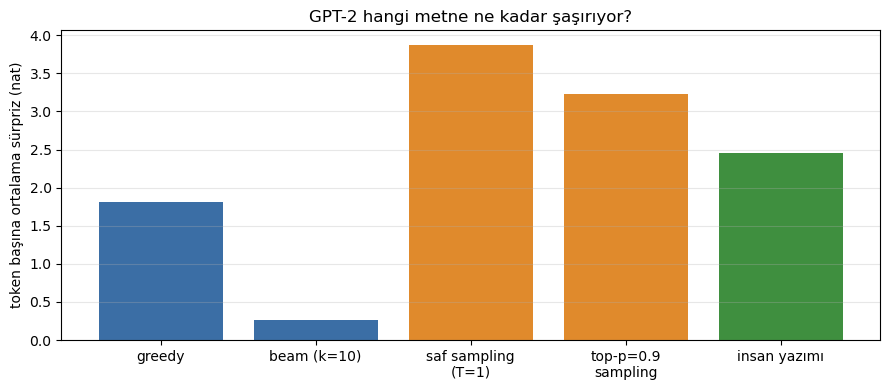

In [12]:
P_INSAN = "The Eiffel Tower is a wrought-iron lattice tower on the Champ de Mars in Paris, France."
INSAN = (" It is named after the engineer Gustave Eiffel, whose company designed and built the tower. "
         "Locally nicknamed the Iron Lady, it was constructed as the centerpiece of the 1889 World's Fair.")

def ort_surpriz(ids, prompt=P_INSAN):
    s, n = devam_nll(gpt, tok_gpt, prompt, ids)
    return s / n

sonuclar = {}
for ad, ayar in [("greedy", {}), ("beam (k=10)", dict(num_beams=10, length_penalty=0.0, early_stopping=False)),
                 ("saf sampling\n(T=1)", dict(sample=True)), ("top-p=0.9\nsampling", dict(sample=True, top_p=0.9))]:
    vals = []
    for seed in range(10):                                   # sampling'te 10 farklı örneğin ortalaması
        _, ids = uret(gpt, tok_gpt, P_INSAN, n_token=45, seed=seed, **ayar)
        vals.append(ort_surpriz(ids[0]))
        if not ayar.get("sample"): break                     # greedy/beam deterministik: 1 kez yeter
    sonuclar[ad] = float(np.mean(vals))
sonuclar["insan yazımı"] = ort_surpriz(tok_gpt(INSAN, add_special_tokens=False).input_ids)

for ad, v in sonuclar.items():
    print(f"{ad.replace(chr(10), ' '):<22} ortalama sürpriz: {v:.2f} nat/token  (perplexity {math.exp(v):.1f})")

plt.figure(figsize=(9, 4))
renk = ["#3b6ea5", "#3b6ea5", "#e08a2c", "#e08a2c", "#3f8f3f"]
plt.bar(list(sonuclar), list(sonuclar.values()), color=renk)
plt.ylabel("token başına ortalama sürpriz (nat)"); plt.title("GPT-2 hangi metne ne kadar şaşırıyor?")
plt.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.savefig("surprisal_comparison.png", dpi=130); plt.show()

**Ne gördük?**

- **Beam (0.26 nat/token, perplexity 1.3) ve greedy (1.82)** GPT-2'nin kendi gözünde çok "rahat" metinler: neredeyse hiç şaşırmıyor. **İnsan yazımı metin 2.45** (perplexity 11.6): beam'in ~9 katı sürprizli. İnsanlar modelin en olası bulduğu şeyi yazmıyor; sürprizli ama anlamlı kelimeler seçiyor.
- **Saf sampling (3.87)** ise insandan da sürprizli: kuyruktan çekilen token'lar GPT-2'yi de şaşırtıyor. **Top-p=0.9 (3.23)** buna en yakın "makul" sampling ama hâlâ insanın üstünde.
- Yani iyi metin, olasılığın **en tepesi (beam) ile en dibi (saf sampling) arasında** bir yerde. Decoding'in işi bu aralığı yakalamak.
- Dikkat: tek bir insan paragrafı (iki cümle) ve küçük bir model. Sayıların büyüklük sırası güvenilir (0.26 ≪ 2.45 < 3.87), küçük farklar gürültü. Bu, Holtzman ve ark.'nın (2019) daha büyük ölçekte gösterdiği bulguyla aynı yönde.

## 4) Sampling ve temperature: zar at, ama zarı ayarla

### Sezgi

**Sampling:** dağılımdan **olasılığına göre** bir token çek. %46'lık token 100 çekilişte ~46 kez, %0,01'lik ~0-1 kez çıkar. Sonuç: her seferinde farklı metin (çeşitlilik), ve greedy'deki gibi tek bir döngüye hapsolmak yok. Bedeli: kötü bir token çekme ihtimali hiç sıfır değil.

**Temperature (T):** zarın ne kadar "yüklü" olduğu. Mekanik çok basit: softmax'tan **önce** logit'leri `T`'ye bölüyoruz.

- `T < 1`: dağılım **sivrilir**. En olası token daha da baskın olur (soğuk, muhafazakâr). `T → 0` greedy'ye yaklaşır.
- `T = 1`: modelin ham dağılımı.
- `T > 1`: dağılım **yayvanlaşır**. Nadir token'lar şansını artırır (sıcak, maceracı). `T → ∞` tamamen rastgele.

Sıcak suda moleküller her yöne savrulur, soğukta yerlerinde kalır; benzetme tutuyor. Aynı dağılımı üç sıcaklıkta görelim.

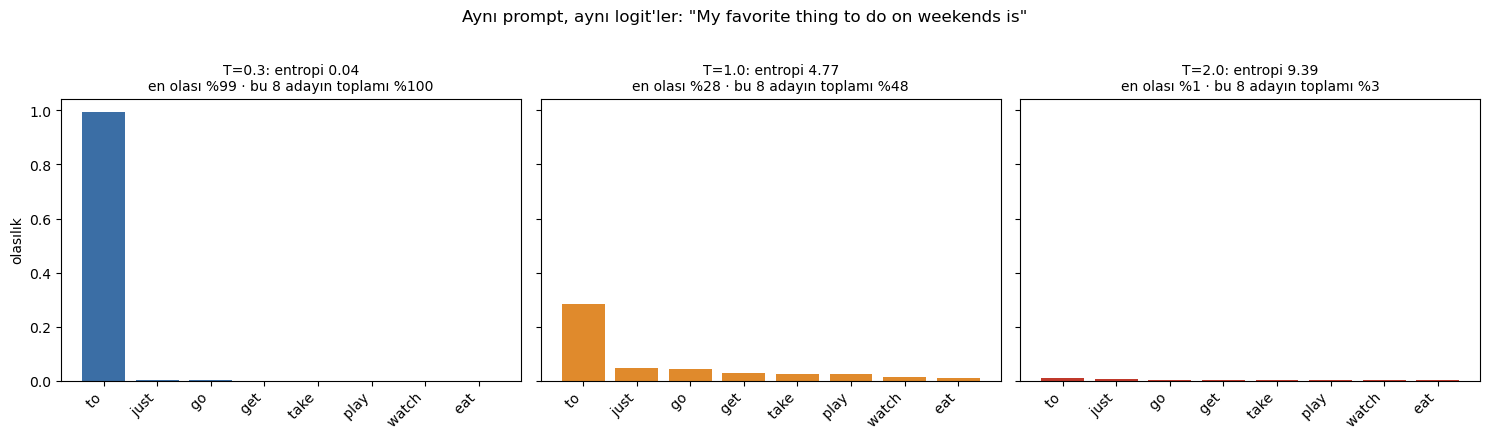

In [13]:
prompt_t = "My favorite thing to do on weekends is"
logits = gpt(**tok_gpt(prompt_t, return_tensors="pt")).logits[0, -1].float()
aday = torch.topk(torch.softmax(logits, -1), 8).indices            # T=1'deki en olası 8 aday sabit kalsın

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
for ax, T, renk in zip(axes, [0.3, 1.0, 2.0], ["#3b6ea5", "#e08a2c", "#c0392b"]):
    p = torch.softmax(logits / T, -1)
    ax.bar(range(8), p[aday].numpy(), color=renk)
    ax.set_xticks(range(8)); ax.set_xticklabels([repr(tok_gpt.decode(int(i)))[1:-1] for i in aday], rotation=45, ha="right")
    ax.set_title(f"T={T}: entropi {entropi(p):.2f}\nen olası %{100*p[aday[0]]:.0f} · bu 8 adayın toplamı %{100*p[aday].sum():.0f}", fontsize=10)
axes[0].set_ylabel("olasılık")
plt.suptitle(f"Aynı prompt, aynı logit'ler: \"{prompt_t}\"", y=1.02)
plt.tight_layout(); plt.savefig("temperature_effect.png", dpi=130, bbox_inches="tight"); plt.show()

**Ne gördük?**

- **T=0.3:** `to` %99, entropi 0.04. Dağılım o kadar sivrildi ki sampling neredeyse greedy. **T=1:** modelin ham dağılımı (`to` %28, entropi 4.77). **T=2:** en olası token %1, bu 8 adayın toplamı %3, entropi 9.39. Dağılım düzleşti ve sözlüğün geri kalanı (%97) oyuna girdi.
- Üç grafik **aynı logit'lerden** çıktı; tek fark softmax'tan önceki bölme işlemi. Temperature, modele yeni bir şey öğretmiyor, sadece "ne kadar cesur davranayım" ayarı.

### Tuzak: "varsayılan ayarlar" nereden geliyor?

`generate(do_sample=True)` yazınca tam olarak ne olur? Her modelin yanında bir `generation_config.json` geliyor ve **senin yazmadığın ayarlar oradan doldurulur**. Üç modelimizin ayarlarına ve "saf" sampling ile farkına bakalım. (Bu yüzden `uret` fonksiyonumuz T, top-k, top-p ve repetition_penalty'yi **açıkça** veriyor.)

In [14]:
from transformers import GenerationConfig
alanlar = ["do_sample", "temperature", "top_k", "top_p", "repetition_penalty"]
print(f"{'model':<28}" + "".join(f"{a:>20}" for a in alanlar))
for ad in ["gpt2", "Qwen/Qwen2.5-0.5B", "Qwen/Qwen2.5-0.5B-Instruct"]:
    g = GenerationConfig.from_pretrained(ad)
    print(f"{ad:<28}" + "".join(f"{str(getattr(g, a, None)):>20}" for a in alanlar))

# GPT-2'de do_sample=True yazıp başka bir şey vermezsek 'saf' sampling mi oluyor, yoksa gizli bir top-k mi var?
xx = tok_gpt(PROMPT, return_tensors="pt")
def ornek(**kw):
    torch.manual_seed(0)
    return gpt.generate(**xx, max_new_tokens=30, do_sample=True, pad_token_id=tok_gpt.eos_token_id, **kw)[0]
v, k50, k0 = ornek(), ornek(top_k=50), ornek(top_k=0)
print("\nsadece do_sample=True  ==  top_k=50 :", torch.equal(v, k50))
print("sadece do_sample=True  ==  top_k=0 (saf sampling):", torch.equal(v, k0))

model                                  do_sample         temperature               top_k               top_p  repetition_penalty
gpt2                                        None                None                None                None                None
Qwen/Qwen2.5-0.5B                          False                None                None                None                None
Qwen/Qwen2.5-0.5B-Instruct                  True                 0.7                  20                 0.8                 1.1

sadece do_sample=True  ==  top_k=50 : True
sadece do_sample=True  ==  top_k=0 (saf sampling): False


**Ne gördük?**

- GPT-2'nin `generation_config`'i boş; Qwen base `do_sample=False`. Ama **Qwen Instruct** yanında hazır bir paket getiriyor: `do_sample=True`, `temperature=0.7`, `top_k=20`, `top_p=0.8` ve **`repetition_penalty=1.1`**. Biz bunları yazmasak da `generate` bunlara başvurabiliyor.
- Deneyle: GPT-2'de sadece `do_sample=True` yazmak **`top_k=50` yazmakla birebir aynı** çıktıyı veriyor (`True`), saf sampling (`top_k=0`) ile aynı değil (`False`). Yani Hugging Face'te `do_sample=True` aslında "top-k=50 sampling".
- Üç ders: (1) Kıyas yaparken **bütün ayarları açık yaz** (`uret` ve `rag_uret` bu yüzden hepsini veriyor). (2) 07'deki `sohbet()` fonksiyonu `do_sample=False` yazmasına rağmen Instruct'ın **gizli `repetition_penalty=1.1`**'ini uyguluyordu; bunun RAG'deki etkisini 8d'de ölçeceğiz. (3) Başkasının sonucunu tekrar edemiyorsan önce `generation_config`'e bak.

### Sıcaklığı büyütünce ne oluyor? (sayılarla)

Aynı unicorn prompt'undan her sıcaklıkta **8 örnek** üretiyoruz (top-k ve top-p kapalı: sadece sıcaklığın etkisi). Üç sayı:

- **tekrar oranı:** metin kendini ne kadar tekrar ediyor (düşük iyi).
- **çeşitlilik:** 8 örnek birbirinden ne kadar farklı (yüksek = çeşitli).
- **hakem bit/karakter:** üreten model GPT-2; ama metni okuyup "ne kadar şaşırdım" diyecek **bağımsız bir hakem** var: Qwen2.5-0.5B (daha büyük, daha çok veriyle eğitilmiş). Düşük = akıcı ve olası; çok yüksek = saçma. (GPT-2 kendi çıktısını değerlendirseydi kendi hatalarını affederdi; bu yüzden ayrı hakem.)

In [15]:
print(f"{'strateji':<12}{'tekrar':>8}{'çeşitlilik':>12}{'hakem bpc':>11}   ilk örnekten bir parça")
for T in [0.3, 0.7, 1.0, 1.5]:
    metinler, _ = kosu(f"T={T}", n=8, n_token=60, sample=True, T=T)
    r = SONUC_KAL[f"T={T}"]
    print(f"{'T='+str(T):<12}{r['tekrar']:>8.2f}{r['cesit']:>12.2f}{r['bpc']:>11.2f}   {metinler[0].strip()[:110]!r}")

strateji      tekrar  çeşitlilik  hakem bpc   ilk örnekten bir parça
T=0.3           0.11        0.65       0.63   'The researchers said that the unicorns were found in a field near the site of a massive landslide in the regio'
T=0.7           0.00        0.91       0.83   'The "unicorns" are believed to live in the area for a few hundred years.\n\n"This is a unique and important disc'
T=1.0           0.00        0.99       1.32   'The "surprise" was that the animals took any requests for a marriage proposal they received rather than the id'
T=1.5           0.00        1.00       2.55   'Using "surveillance and surveavior objective standards" mobile valley trappers combed barechesteding, scant pi'


**Ne gördük?**

- **Bedava öğle yemeği yok.** T=0.3'ten T=1.5'e çıkarken çeşitlilik 0.65 → 0.91 → 0.99 → 1.00 oluyor (8 örnek birbirine hiç benzemiyor) ama hakem bit/karakter 0.63 → 0.83 → 1.32 → 2.55: hakem, metni giderek daha az akıcı buluyor.
- **T=1.5'te metin kelime salatası:** "Using 'surveillance and surveavior objective standards' mobile valley trappers combed barechesteding, scant pi..." Hakem bu metne T=0.3'tekinden ~4 kat daha çok şaşırıyor.
- **Tekrar sorunu T=0.7'den itibaren yok** (0.00): sampling greedy'nin döngüsünü çözdü. Ama yerine başka bir sorun geldi: sıcaklık yükseldikçe kalite düşüyor. T=1.0'daki örnek dilbilgisi olarak düzgün ama anlamı kayıyor ("the animals took any requests for a marriage proposal ...").
- Sıcaklık, kuyruktaki token'ları **cesaretlendiriyor** ama kuyruğu **kesmiyor**. Kesme işi top-k ve top-p'nin (sıradaki bölüm).

## 5) Top-k ve top-p: kuyruğu kes

### Sorun: kuyruk

Saf sampling'de, T=1'de bile bir sorun var: sözlükte 50.000 token var. Neredeyse hepsi o bağlamda saçma, ama olasılıkları **sıfır değil**. Küçük küçük hepsi toplanınca büyük bir kütle edebilir: bu **kuyruk**. Her adımda kuyruktan çekiliş şansı %5 olsa, 60 adımda en az bir kez çöp çekme olasılığı ~%95. Üstelik bir kere çöp token seçilince model onu **bağlam** olarak görür ve oradan devam eder; kendi hatasını normalmiş gibi sürdürür.

Çözüm: çekilişten **önce** kuyruğu kes.

- **Top-k:** sadece en olası `k` token'ı tut, gerisini at (Fan ve ark. 2018). `k` sabit.
- **Top-p (nucleus):** olasılıkları büyükten küçüğe topla, toplam `p`'ye ulaşana kadar olan token'ları tut (Holtzman ve ark. 2019). Aday sayısı **dağılıma göre uyarlanır**.

Neden top-p daha mantıklı? Sivri bir dağılımda ("Water boils at 100 degrees" → `Celsius`) 3-4 token yeter. Yayvan bir dağılımda ("Once upon a time, there was a ...") yüzlerce makul seçenek var. Sabit `k=50`, biri için fazla, diğeri için az. Bunu gerçek bir cümlenin her konumunda ölçelim: **%90 kütleyi toplamak için kaç token gerekiyor?**

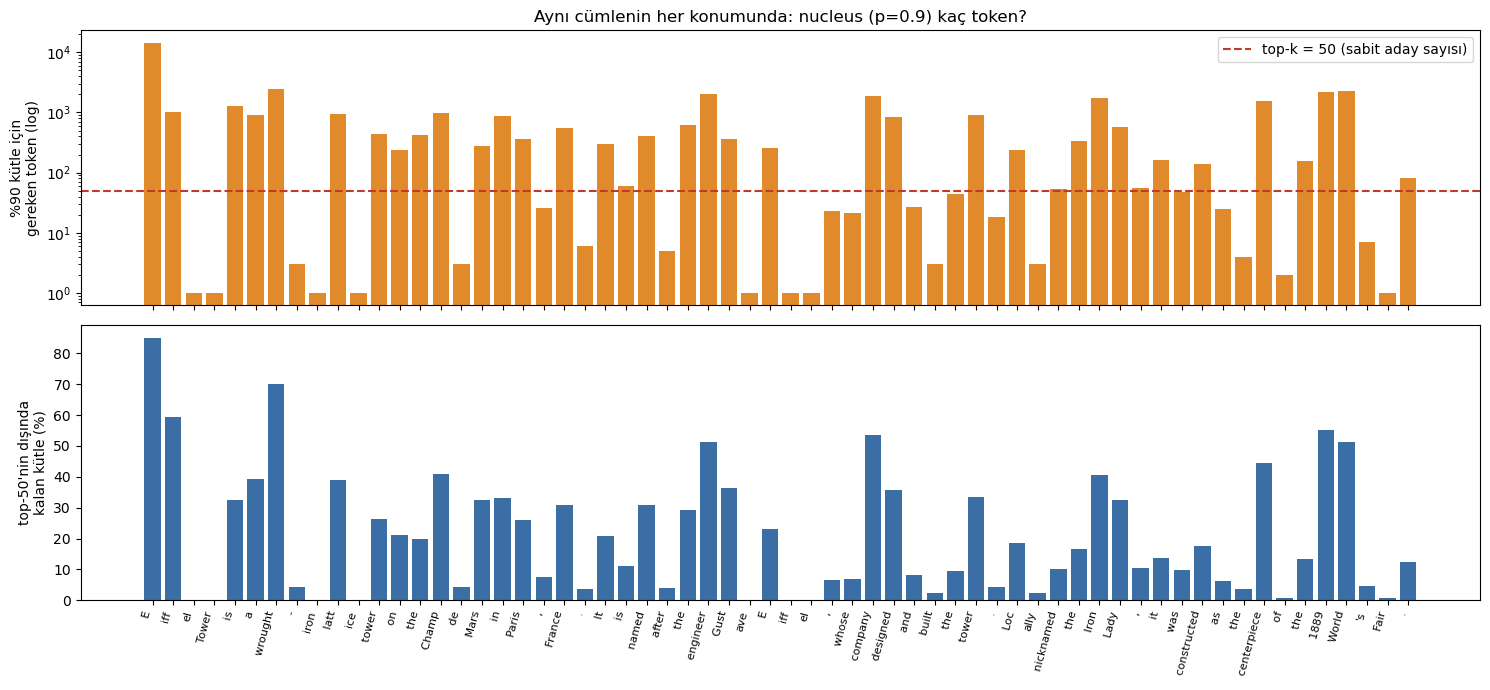

nucleus boyutu: ortanca 159 token | en küçük 1 | en büyük 14395
nucleus ≤ 3 token olan konumlar: %21 | nucleus > 50 token olan konumlar: %60
top-50 dışında kalan ortalama kütle: %21.1  →  60 adımda en az bir kez kuyruktan çekme olasılığı ~%100


In [16]:
CUMLE = P_INSAN + INSAN      # 3. bölümde tanımladığımız insan yazımı paragraf
ids = tok_gpt(CUMLE, return_tensors="pt").input_ids
P = torch.softmax(gpt(ids).logits[0].float(), -1)      # P[i]: i. token'dan SONRA gelecek token'ın dağılımı
n90, kuyruk = [], []
for pos in range(ids.shape[1] - 1):
    s, _ = torch.sort(P[pos], descending=True); c = torch.cumsum(s, 0)
    n90.append(int((c < 0.9).sum()) + 1)               # %90'a ulaşmak için gereken token sayısı
    kuyruk.append(float(1 - c[49]))                    # top-50'nin DIŞINDA kalan kütle
n90, kuyruk = np.array(n90), np.array(kuyruk)
etiket = [repr(tok_gpt.decode(int(i)))[1:-1] for i in ids[0, 1:]]

fig, (a1, a2) = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
a1.bar(range(len(n90)), n90, color="#e08a2c"); a1.set_yscale("log")
a1.axhline(50, color="#c0392b", ls="--", label="top-k = 50 (sabit aday sayısı)"); a1.legend(loc="upper right")
a1.set_ylabel("%90 kütle için\ngereken token (log)"); a1.set_title("Aynı cümlenin her konumunda: nucleus (p=0.9) kaç token?")
a2.bar(range(len(kuyruk)), kuyruk * 100, color="#3b6ea5"); a2.set_ylabel("top-50'nin dışında\nkalan kütle (%)")
a2.set_xticks(range(len(etiket))); a2.set_xticklabels(etiket, rotation=75, ha="right", fontsize=8)
plt.tight_layout(); plt.savefig("nucleus_size.png", dpi=130); plt.show()

print(f"nucleus boyutu: ortanca {int(np.median(n90))} token | en küçük {n90.min()} | en büyük {n90.max()}")
print(f"nucleus ≤ 3 token olan konumlar: %{100*np.mean(n90 <= 3):.0f} | nucleus > 50 token olan konumlar: %{100*np.mean(n90 > 50):.0f}")
print(f"top-50 dışında kalan ortalama kütle: %{100*kuyruk.mean():.1f}  →  60 adımda en az bir kez kuyruktan çekme olasılığı ~%{100*(1-(1-kuyruk.mean())**60):.0f}")

**Ne gördük?**

- **%90 kütleyi toplamak için gereken token sayısı konuma göre 1 ile 14.394 arasında değişiyor** (ortanca 159). En büyük nucleus cümlenin ilk token'ında (`The`'den sonra hemen her şey gelebilir). `iff`, `el`, `ave` gibi bir kelimenin devamı olan konumlarda ise nucleus **tek token**: kelimenin geri kalanı belli.
- Konumların **%21'inde nucleus ≤ 3 token** (sivri), **%60'ında 50'den fazla** (yayvan). Sabit `top-k=50` iki yönde de yanlış: sivri konumlarda 47+ gereksiz aday bırakıyor, yayvan konumlarda (yüzlerce-binlerce makul seçenek) gerçek adayları kesiyor. **Top-p adayların sayısını dağılıma göre kendiliğinden ayarlıyor.**
- **Kuyruk kütlesi ağır:** top-50'nin dışında kalan kütle ortalama %21 (alttaki panel; ilk konumda %85). Saf sampling'de her adımda ~%21 şansla bu bölgeden token çekiliyor; 60 adımda en az bir kez çekme olasılığı pratikte %100. (Kuyruktaki her token çöp değil; 51. sıradaki token makul bir kelime olabilir. Ama 7. bölümde kuyruğun içinde gerçekten çöp de yaşadığını göreceğiz.)
- Dikkat: bu GPT-2 small ve nadir özel isimlerle dolu bir paragraf; büyük modellerde ve sıradan metinde kuyruk daha ince olur ama sıfır olmaz.

### Çekirdeği elle yazalım: top-k ve top-p filtresi

İki filtre de aynı şeyi yapıyor: **atılacak token'ların logit'ini −∞ yapmak** (softmax sonra onlara 0 verir, kalanlar kendiliğinden yeniden normalize olur). Sonra Hugging Face'in kendi `TopKLogitsWarper` ve `TopPLogitsWarper`'ı ile aynı token'ları tuttuğumuzu doğrulayalım.

In [17]:
def filtrele(logits, top_k=0, top_p=1.0):
    """logits -> kuyruğu kesilmiş logits (atılan token'lar -inf). Sıra: önce top-k, sonra top-p."""
    logits = logits.clone()
    if top_k > 0:
        esik = torch.topk(logits, top_k).values[-1]
        logits[logits < esik] = -float("inf")                          # k'inci en iyiden küçükler gitsin
    if top_p < 1.0:
        sirali, idx = torch.sort(logits, descending=True)
        p = torch.softmax(sirali, -1)
        atilacak = (torch.cumsum(p, -1) - p) >= top_p                  # kendinden ÖNCEKİ toplam zaten p'ye ulaştıysa at
        logits[idx[atilacak]] = -float("inf")
    return logits

from transformers import TopKLogitsWarper, TopPLogitsWarper
lg = gpt(**tok_gpt("Once upon a time, there was a", return_tensors="pt")).logits[0, -1].float()
print(f"{'ayar':<18}{'bizim filtre':>14}{'HF warper':>11}{'farklı token sayısı':>21}")
for ad, ayar, warper in [("top_k=50", dict(top_k=50), TopKLogitsWarper(50)),
                         ("top_k=10", dict(top_k=10), TopKLogitsWarper(10)),
                         ("top_p=0.9", dict(top_p=0.9), TopPLogitsWarper(0.9)),
                         ("top_p=0.5", dict(top_p=0.5), TopPLogitsWarper(0.5))]:
    bizim = torch.isfinite(filtrele(lg, **ayar))
    hf = torch.isfinite(warper(None, lg[None].clone())[0])
    print(f"{ad:<18}{int(bizim.sum()):>14}{int(hf.sum()):>11}{int((bizim != hf).sum()):>21}")

ayar                bizim filtre  HF warper  farklı token sayısı
top_k=50                      50         50                    0
top_k=10                      10         10                    0
top_p=0.9                   3651       3652                    1
top_p=0.5                    245        245                    0


**Ne gördük?**

- **Top-k filtresi Hugging Face'inkiyle birebir aynı** (50 ve 10'da 0 farklı token). **Top-p'de** 0.5'te birebir aynı, 0.9'da 3651'e karşı 3652: **1 token fark**. Sebebi büyük olasılıkla sınırdaki tek bir token'ın kümülatif toplamda küçük bir float yuvarlama farkıyla ters tarafa düşmesi (biz toplamı büyükten küçüğe, Hugging Face küçükten büyüğe alıyor). Mantık aynı; 3651 aday arasında 1 token'ın üretime etkisi yok.
- Yani `generate`'in sampling ayarlarının çekirdeği ~10 satır: **atılacak token'ların logit'ini −∞ yap, geri kalanı softmax'a bırak.** Softmax kalanları kendiliğinden yeniden normalize ediyor.

### Üç düğme birlikte: filtre hattı

`generate`'in sampling'te yaptığı işlem sırayla şu: **sıcaklığı uygula → top-k ile kes → top-p ile kes → kalanı yeniden normalize et → zar at.** Aşağıda tek bir gerçek dağılım (Qwen, "Water boils at 100 degrees" sonrası) bu hattan geçiyor. **Gri** çubuklar o aşamada atılan token'lar.

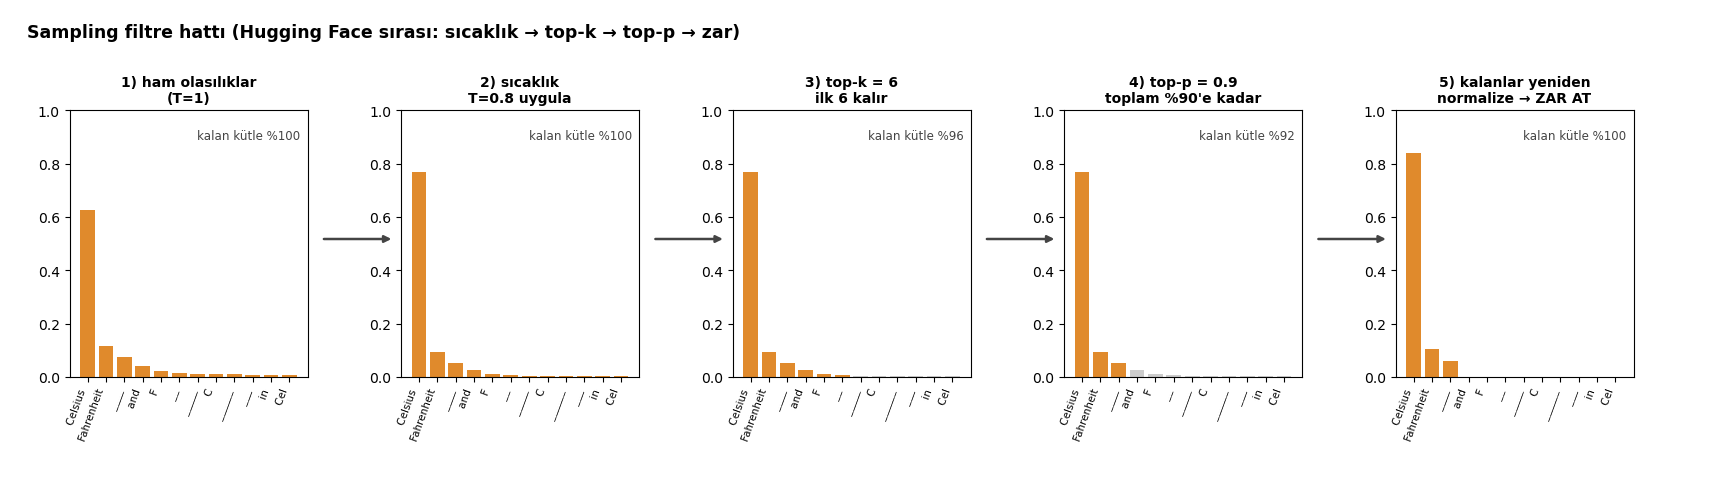

In [18]:
def draw_filter(save="filter_pipeline.png", T=0.8, k=6, p=0.9):
    pr = "Water boils at 100 degrees"
    lg = qwen_base(**tok_q(pr, return_tensors="pt")).logits[0, -1].float()
    p0 = torch.softmax(lg, -1)
    aday = torch.topk(p0, 12).indices
    p1 = torch.softmax(lg / T, -1)                                          # sıcaklık uygulandı
    mk = torch.isfinite(filtrele(lg / T, top_k=k)).float()                  # top-k maskesi
    mkp = torch.isfinite(filtrele(lg / T, top_k=k, top_p=p)).float()        # top-k + top-p maskesi
    asamalar = [
        (f"1) ham olasılıklar\n(T=1)", p0, torch.ones_like(p0)),
        (f"2) sıcaklık\nT={T} uygula", p1, torch.ones_like(p1)),
        (f"3) top-k = {k}\nilk {k} kalır", p1, mk),
        (f"4) top-p = {p}\ntoplam %{int(p*100)}'e kadar", p1, mkp),
        (f"5) kalanlar yeniden\nnormalize → ZAR AT", p1 * mkp / (p1 * mkp).sum(), torch.ones_like(p1)),
    ]
    fig = plt.figure(figsize=(17, 4.6))
    bg = fig.add_axes([0, 0, 1, 1]); bg.axis("off"); bg.set_xlim(0, 1); bg.set_ylim(0, 1)
    for i, (baslik, dagilim, maske) in enumerate(asamalar):
        ax = fig.add_axes([0.035 + i * 0.195, 0.2, 0.14, 0.58])
        deger = dagilim[aday].numpy(); tutuldu = maske[aday].numpy() > 0
        ax.bar(range(12), deger, color=["#e08a2c" if t else "#cccccc" for t in tutuldu])
        ax.set_ylim(0, 1); ax.set_xticks(range(12))
        ax.set_xticklabels([repr(tok_q.decode(int(j)))[1:-1] for j in aday], rotation=70, ha="right", fontsize=7.5)
        kalan = float((dagilim * maske).sum())
        ax.set_title(baslik, fontsize=10, fontweight="bold")
        ax.text(0.97, 0.93, f"kalan kütle %{100*kalan:.0f}", transform=ax.transAxes, ha="right", va="top", fontsize=8.5, color="#444")
        if i < 4:
            ok_ciz(bg, 0.035 + i * 0.195 + 0.148, 0.5, 0.035 + (i + 1) * 0.195 - 0.004, 0.5)
    bg.text(0.01, 0.97, "Sampling filtre hattı (Hugging Face sırası: sıcaklık → top-k → top-p → zar)", fontsize=12.5, fontweight="bold", va="top")
    plt.savefig(save, dpi=130, bbox_inches="tight"); plt.show()
draw_filter()

**Ne gördük?**

- **2) Sıcaklık (T=0.8):** `Celsius` %63'ten ~%77'ye çıktı; dağılım sivrildi.
- **3) Top-k=6:** ilk 6 aday kaldı; toplam kütlenin %96'sı hayatta.
- **4) Top-p=0.9:** kütle %92'ye indi; gri çubuklar (`and`, `F`, `_` ...) atıldı. Burada top-p, top-k'nın bıraktığı adaylardan 3 tanesini daha elemiş.
- **5) Yeniden normalize:** `Celsius` ~%84, `Fahrenheit` ~%10, bir boşluk token'ı ~%6. Zar **sadece 3 aday** arasında atılıyor; 50.000 tokenlık sözlükten geriye kalan bu.
- Sıra önemli: Hugging Face **önce sıcaklığı** uyguluyor, sonra kesiyor. Bu, 8b'de top-p'nin neden yüksek sıcaklıkta işe yaramadığını açıklayacak.

### Hepsini yan yana: kalite–çeşitlilik dengesi

Şimdiye kadar baktığımız ve birkaç yeni strateji için aynı unicorn prompt'undan 8'er örnek üretip aynı üç sayıyı ölçelim. Sonra hepsini tek grafikte toplayalım: **x ekseni çeşitlilik**, **y ekseni hakem bit/karakter** (aşağısı daha akıcı), **renk tekrar oranı**. Greedy ve beam deterministik olduğu için 8 kopya aynı metin; çeşitlilikleri düşük çıkması bundan.

Not: tek prompt, 8 örnek. Büyüklük sırası güvenilir, küçük farklar gürültü.

strateji              tekrar  çeşitlilik  hakem bpc
greedy                  0.30        0.09       0.57
beam 3                  0.21        0.09       0.48
beam 5                  0.05        0.12       0.49
beam 10                 0.21        0.09       0.45
T=0.3                   0.11        0.65       0.63
T=0.7                   0.00        0.91       0.83
T=1.0                   0.00        0.99       1.32
T=1.5                   0.00        1.00       2.55
top-k 10                0.03        0.87       0.77
top-k 50                0.00        0.96       0.93
top-p 0.95              0.00        0.99       1.35
top-p 0.9               0.00        0.97       1.13
T=0.7 + top-p 0.9       0.01        0.82       0.72


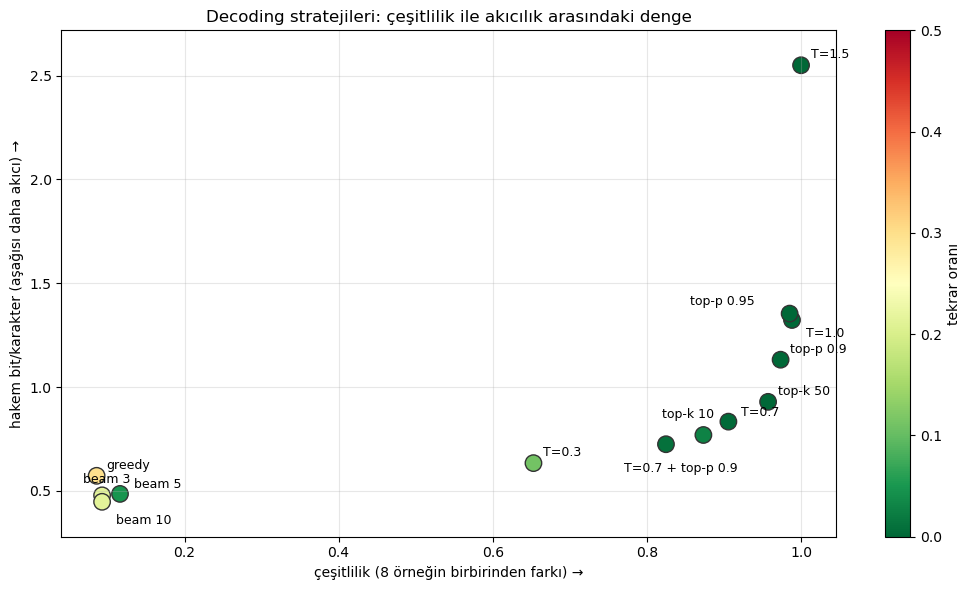


--- top-p 0.9 ve T=1.0 saf sampling'ten birer örnek ---
top-p 0.9 : The "surprise" was that the animals took shelter from a storm, in what they thought was tropical rain. However, what struck them was a growing warmth. A team of scientists decided to investigate, hoping to find the "lost gods".  As soon as they brought the cri
T=1.0 saf : The "surprise" was that the animals took any requests for a marriage proposal they received rather than the idea of a child and insists they remain happy instead of drawn to the family.  According to an early report by AccuWeather WUWT July 23, these animals b


In [19]:
yeni = [("top-k 10", dict(sample=True, top_k=10)), ("top-k 50", dict(sample=True, top_k=50)),
        ("top-p 0.95", dict(sample=True, top_p=0.95)), ("top-p 0.9", dict(sample=True, top_p=0.9)),
        ("T=0.7 + top-p 0.9", dict(sample=True, T=0.7, top_p=0.9))]
ornekler = {}
for ad, ayar in yeni:
    ornekler[ad], _ = kosu(ad, n=8, n_token=60, **ayar)

print(f"{'strateji':<20}{'tekrar':>8}{'çeşitlilik':>12}{'hakem bpc':>11}")
for ad, r in SONUC_KAL.items():
    print(f"{ad:<20}{r['tekrar']:>8.2f}{r['cesit']:>12.2f}{r['bpc']:>11.2f}")

fig, ax = plt.subplots(figsize=(10.5, 6))
adlar = list(SONUC_KAL)
x = [SONUC_KAL[a]["cesit"] for a in adlar]; y = [SONUC_KAL[a]["bpc"] for a in adlar]; c = [SONUC_KAL[a]["tekrar"] for a in adlar]
sc = ax.scatter(x, y, c=c, cmap="RdYlGn_r", s=140, edgecolor="#333", vmin=0, vmax=max(0.5, max(c)))
ofset = {"beam 3": (-14, 9), "beam 5": (10, 4), "beam 10": (10, -16), "T=0.7": (9, 4), "top-k 10": (-30, 12),
         "T=0.7 + top-p 0.9": (-30, -20), "top-p 0.95": (-72, 6), "T=1.0": (10, -12)}
for a, xi, yi in zip(adlar, x, y):
    ax.annotate(a, (xi, yi), textcoords="offset points", xytext=ofset.get(a, (7, 5)), fontsize=9)
ax.set_xlabel("çeşitlilik (8 örneğin birbirinden farkı) →"); ax.set_ylabel("hakem bit/karakter (aşağısı daha akıcı) →")
ax.set_title("Decoding stratejileri: çeşitlilik ile akıcılık arasındaki denge"); ax.grid(alpha=0.3); ax.margins(y=0.08)
plt.colorbar(sc, label="tekrar oranı"); plt.tight_layout(); plt.savefig("quality_diversity.png", dpi=130); plt.show()

print("\n--- top-p 0.9 ve T=1.0 saf sampling'ten birer örnek ---")
print("top-p 0.9 :", ornekler["top-p 0.9"][0].strip()[:260].replace("\n", " "))
print("T=1.0 saf :", kume(gpt, tok_gpt, PROMPT, n=8, n_token=60, sample=True, T=1.0)[0][0].strip()[:260].replace("\n", " "))

**Ne gördük?**

- **Sol alt (greedy ve beam):** çeşitlilik ~0.1 (8 örnek kopya) ve hakem bpc 0.45-0.57: en "akıcı" görünüyorlar ama tekrar oranları 0.05-0.30 ve **hep aynı metni üretiyorlar**.
- **Sağ üst (saf T=1.0 ve T=1.5):** çeşitlilik ~1.0 ama bpc 1.32 ve 2.55: hakem metni akıcı bulmuyor.
- **Orta bölge (tatlı nokta):** `top-k 10`, `top-k 50`, `top-p 0.9` ve özellikle **`T=0.7 + top-p 0.9`** (çeşitlilik 0.82, bpc 0.72): hem çeşitli hem akıcı. Sıcaklığı düşürüp kuyruğu kesmek ikisini birlikte kullandığımızda en iyi dengeyi verdi.
- Küçük farklar gürültü: örneğin `top-p 0.95` (1.35) ile saf `T=1.0` (1.32) neredeyse aynı; tek prompt, 8 örnek. Büyüklük sırasına güven, küçük sıralamalara değil.
- **Örnek metinler:** top-p 0.9 ile saf T=1 aynı yerden başlıyor ("The 'surprise' was that the animals took..."). Saf T=1 bir noktada kopuyor ("marriage proposal ... AccuWeather WUWT"); top-p 0.9 bütünlüğünü daha uzun koruyor ama o da "lost gods" gibi şeyler uyduruyor. **Decoding modelin bilmediği bilgiyi vermez; sadece mevcut dağılımın hangi kısmından çekeceğimizi seçer.**

## 6) Tekrar cezası: son çare, yan etkisiyle

Greedy ve beam'in tekrar döngüsünü sampling'siz kırmak için iki yaygın yama var:

- **`repetition_penalty`:** daha önce geçmiş token'ların skorunu cezalandırır (1.0 = ceza yok).
- **`no_repeat_ngram_size=n`:** aynı `n` token'lık dizinin ikinci kez çıkmasını **yasaklar**.

İkisi de metnin kalitesini değil sadece "tekrar etmeme" kuralını zorluyor. Etkisini ve ne kadar işe yaradığını görelim (GPT-2, aynı prompt).

In [20]:
sec = [("greedy", dict()), ("greedy + rep 1.3", dict(rep=1.3)), ("greedy + no_repeat 3", dict(no_repeat_ngram_size=3)),
       ("beam 5", dict(num_beams=5, length_penalty=0.0, early_stopping=False)),
       ("beam 5 + no_repeat 3", dict(num_beams=5, length_penalty=0.0, early_stopping=False, no_repeat_ngram_size=3))]
print(f"{'strateji':<24}{'tekrar':>8}{'hakem bpc':>11}   ilk 130 karakter")
for ad, ayar in sec:
    if ad in SONUC_KAL:                                   # greedy ve beam 5'i 3-5. bölümlerde zaten ölçtük
        metinler, _ = kume(gpt, tok_gpt, PROMPT, n=1, n_token=60, **ayar)
    else:
        metinler, _ = kosu(ad, n=8, n_token=60, **ayar)
    r = SONUC_KAL[ad]
    print(f"{ad:<24}{r['tekrar']:>8.2f}{r['bpc']:>11.2f}   {metinler[0].strip()[:130]!r}")

strateji                  tekrar  hakem bpc   ilk 130 karakter
greedy                      0.30       0.57   'The researchers found that the animals were able to survive in a climate that was warmer than the average for the region.\n\n"The an'
greedy + rep 1.3            0.00       2.28   '(Photo: Getty Images)'
greedy + no_repeat 3        0.00       0.88   'The researchers found that the animals were able to survive in a climate that was warmer than the average for the region.\n.\n, whic'
beam 5                      0.05       0.49   'The researchers, from the University of California, San Diego, and the University of California, Santa Cruz, found that the unicor'
beam 5 + no_repeat 3        0.00       0.54   'The researchers, from the University of California, San Diego, and the National Science Foundation (NSF), found that the unicorns,'


**Ne gördük?**

- **`repetition_penalty=1.3`:** tekrar 0.30 → 0.00 oldu ama hakem bpc 0.57 → 2.28'e fırladı ve metin tek bir `(Photo: Getty Images)` satırına dönüştü. Ceza, modeli doğal devamdan uzaklaştırıp ilk bulduğu "başka bir şeye" itti.
- **`no_repeat_ngram_size=3`:** tekrar 0.00, bpc 0.88. Metin ilk cümleden sonra bozuk parçalara düşüyor (`.\n, whic...`): model aynı cümleyi sürdürmek istiyor, yasak ona yol vermiyor.
- **Beam + `no_repeat_ngram_size=3`:** tekrar 0.05 → 0.00, bpc 0.49 → 0.54: en küçük zarar. Muhtemel sebep: beam birden çok rota taşıdığı için yasaklanan yolun yerine hemen başka bir rota bulabiliyor (Hugging Face blogunun önerdiği kombinasyon).
- Ders: ceza **semptomu** bastırıyor, nedeni (modelin kendi cümlesini pekiştirmesi) değil. Ve 8d'de göreceğimiz gibi, **RAG'de tehlikeli**.

## 7) Türkçe'de aynı ayarlar: kuyruk daha tehlikeli mi?

07'de Türkçe'nin token başına daha çok parçaya bölündüğünü gördük (GPT-2'de Türkçe karakter başına ~0,54 token, İngilizce ~0,21). Aynı uzunlukta bir Türkçe metin **daha çok adım** demek; her adımda kuyruktan çekiliş şansı varsa, daha çok adımda daha çok şans. Üstelik çok dilli bir modelin kuyruğunda başka alfabelerin token'ları da bekliyor (Çince, Tayca...). Qwen ile Türkçe bir prompt'tan 10'ar örnek üretelim ve **Latin dışı harf** içeren örnekleri sayalım (bozuk çıktının kaba ama şeffaf bir göstergesi).

In [21]:
PROMPT_TR = "Bir zamanlar, dağların ardındaki küçük bir köyde yaşlı bir terzi yaşardı."

def yabanci_alfabe(metin):
    """Metindeki harflerin kaçı Latin alfabesi DIŞINDA (Çince, Tayca, Kiril...)? 0 = hiç yok."""
    harf = [c for c in metin if c.isalpha()]
    return sum("LATIN" not in unicodedata.name(c, "") for c in harf) / max(len(harf), 1)

ayarlar_tr = [("greedy", dict()), ("T=1.0 saf", dict(sample=True, T=1.0)), ("T=1.5 saf", dict(sample=True, T=1.5)),
              ("top-k 50", dict(sample=True, top_k=50)), ("top-p 0.9", dict(sample=True, top_p=0.9)),
              ("T=0.7 + top-p 0.9", dict(sample=True, T=0.7, top_p=0.9))]
tr_metin = {}
print(f"{'strateji':<20}{'yabancı harf içeren örnek':>27}{'ort. yabancı harf oranı':>26}{'tekrar':>8}")
for ad, ayar in ayarlar_tr:
    metinler, _ = kume(qwen_base, tok_q, PROMPT_TR, n=10, n_token=50, **ayar)
    tr_metin[ad] = metinler
    yab = [yabanci_alfabe(m) for m in metinler]
    print(f"{ad:<20}{sum(y > 0 for y in yab):>24}/10{100*np.mean(yab):>25.1f}%{np.mean([tekrar_orani(m) for m in metinler]):>8.2f}")

for ad in ["greedy", "T=1.0 saf", "top-p 0.9"]:
    print(f"\n--- {ad} ---")
    for m in tr_metin[ad][:3]:
        print("  •", m.strip()[:150].replace("\n", " "))

strateji              yabancı harf içeren örnek   ort. yabancı harf oranı  tekrar
greedy                                     0/10                      0.0%    0.88
T=1.0 saf                                  7/10                      8.9%    0.01
T=1.5 saf                                 10/10                      8.6%    0.00
top-k 50                                   0/10                      0.0%    0.00
top-p 0.9                                  1/10                      2.5%    0.00
T=0.7 + top-p 0.9                          0/10                      0.0%    0.03

--- greedy ---
  • Bir gün, bir gün, bir gün, bir gün, bir gün, bir gün, bir gün, bir gün, bir gün, bir gün, bir gün, bir gün, bir gün, bir gün, bir gün, bir gün, bir gü
  • Bir gün, bir gün, bir gün, bir gün, bir gün, bir gün, bir gün, bir gün, bir gün, bir gün, bir gün, bir gün, bir gün, bir gün, bir gün, bir gün, bir gü
  • Bir gün, bir gün, bir gün, bir gün, bir gün, bir gün, bir gün, bir gün, bir gün, bir gün, bir gü

**Ne gördük?**

- **Greedy Türkçe:** "Bir gün, bir gün, bir gün, ..." diye sonsuz döngü (tekrar oranı 0.88). İngilizce GPT-2'deki döngüden (0.30-0.43) daha kötü: Qwen 0.5B'nin Türkçesi zayıf, greedy zayıf bir dağılımın tepesine yapışıp kalıyor.
- **Saf T=1.0:** 10 örneğin **7'sinde Latin dışı harf** var (`Ak وحتى`, `Sayda急忙` gibi Arapça ve Çince sızıntıları); **T=1.5'te 10/10**. Bunlar kuyruktan çekilen çöp token'lar ve çoğu kelimenin ortasına düşüyor.
- **Kuyruğu kesmek sızıntıyı siliyor:** top-k 50'de 0/10, top-p 0.9'da 1/10, `T=0.7 + top-p 0.9`'da 0/10.
- **Ama Türkçe düzelmedi:** top-p 0.9 örnekleri ("Zaten bunun yerine saattım haftalık evlenebilirin...") yabancı harf içermiyor ama anlamsız. Kuyruk kesmek **çöp token'ı** engelliyor; **Qwen 0.5B'nin Türkçe bilgisini** artırmıyor. Yine: decoding modelin sınırını aşamaz.
- Hipotezimiz (Türkçe daha çok token → kuyruktan daha çok çekiliş şansı) bu deneyde **doğrudan ölçülmedi**: aynı modelde İngilizce ile Türkçe'yi kıyaslamadık. Güzel bir sonraki soru (tez #15 ve #22 için bir mühendislik ayrıntısı olabilir).

## 8) RAG'e göz kırpan deney: aynı bağlam, farklı decoding

### Soru

07'de RAG'in okuyucusu (Qwen Instruct) hep `do_sample=False` ile çalışıyordu. Gerçek sistemlerde API'lerde sıcaklık varsayılan olarak genelde sıfırdan büyük. Soru: **okuyucuya doğru bilgiyi bağlam olarak verdiğimizde bile, decoding ayarı cevabın doğruluğunu ve tutarlılığını nasıl etkiler?**

Deney kurulumu 07'dekine benzer ama bir fark var: **bulucuyu hatasız varsayıyoruz**. Her soruya doğru pasajı elle veriyoruz, böylece ölçtüğümüz fark sadece decoding'den gelsin (bulucu hatası karışmasın). Bilgiler 07'deki 10 uydurma Karaçam Teknoloji Enstitüsü (KTE) bilgisi; sorular "yeniden yazılmış" test soruları.

Üç alt deney:

- **8a:** Bağlam verince modelin belirsizliği (entropi) ne oluyor?
- **8b:** Bağlam varken sıcaklık ve top-p cevabın doğruluğunu nasıl etkiliyor?
- **8c-d:** Bağlam yokken örnekler birbirini tutuyor mu? Ve `repetition_penalty` RAG'de neden tehlikeli?

Okuyucu modeli yüklüyoruz (bu hücre `float32` yüklüyor, ~2 GB).

In [22]:
tok_qi = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")
qwen_inst = AutoModelForCausalLM.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct", dtype=torch.float32).eval()

# (bilgi cümlesi, cevapta aranacak anahtar, test sorusu): 07'deki 10 uydurma KTE bilgisi
BILGILER = [
 ("Karaçam Teknoloji Enstitüsü 1987 yılında kurulmuştur.", "1987", "Karaçam Teknoloji Enstitüsü ne zaman kurulmuştur?"),
 ("Karaçam Teknoloji Enstitüsü'nün ana kampüsü Eskişehir'dedir.", "Eskişehir", "KTE hangi ilde bulunuyor?"),
 ("Karaçam Teknoloji Enstitüsü'nün rektörü Prof. Dr. Aylin Demirtaş'tır.", "Aylin Demirtaş", "KTE'nin rektörünün adı nedir?"),
 ("Karaçam Teknoloji Enstitüsü'nün maskotu kızıl baykuştur.", "kızıl baykuş", "KTE'nin maskotu hangi hayvandır?"),
 ("Enstitü her mayıs ayında Mavi Kıvılcım Şenliği'ni düzenler.", "Mavi Kıvılcım", "KTE'nin bahar şenliği hangi isimle anılır?"),
 ("Enstitüde yaklaşık 6.400 öğrenci okumaktadır.", "6.400", "KTE'de toplam kaç öğrenci okuyor?"),
 ("Enstitünün ilk açılan bölümü Malzeme Mühendisliği'dir.", "Malzeme Mühendisliği", "KTE'nin en eski bölümü hangisidir?"),
 ("Enstitünün en prestijli bursu Nihat Sarıkaya Bursu'dur.", "Nihat Sarıkaya", "KTE'nin en değerli bursunun adı nedir?"),
 ("Enstitü kütüphanesi haftanın yedi günü 24 saat açıktır.", "24 saat", "KTE kütüphanesi günün hangi saatlerinde açık?"),
 ("Enstitünün takımı 2023'te Kızıl Baykuş adlı roketle irtifa rekoru kırdı.", "Kızıl Baykuş", "KTE'nin 2023 irtifa rekoru hangi roketle gerçekleşti?"),
]

def dogru(cevap, anahtar):
    return all(a.lower() in cevap.lower() for a in anahtar.split("+"))

def sohbet_prompt(soru, baglam=None):
    """07'deki sohbet() ile aynı şablon: bağlam varsa 'sadece bunu kullan' diyoruz."""
    if baglam:
        sistem = "Sadece verilen bilgiye dayanarak, kısa ve tek cümleyle cevap ver. Bilgi yoksa 'Bilmiyorum' de."
        kullanici = f"Bilgi: {baglam}\n\nSoru: {soru}"
    else:
        sistem, kullanici = "Kısa ve tek cümleyle cevap ver.", soru
    return tok_qi.apply_chat_template([{"role": "system", "content": sistem}, {"role": "user", "content": kullanici}],
                                      tokenize=False, add_generation_prompt=True)

def rag_uret(soru, baglam=None, n=1, n_token=24, seed=0, sample=False, T=1.0, top_k=0, top_p=1.0, rep=1.0):
    """Instruct okuyucudan cevap(lar). Ayarlar AÇIKÇA veriliyor (Instruct'ın gizli varsayılanlarını ezmek için)."""
    torch.manual_seed(seed)
    ids = tok_qi(sohbet_prompt(soru, baglam), return_tensors="pt")
    ayar = dict(max_new_tokens=n_token, repetition_penalty=rep, pad_token_id=tok_qi.eos_token_id)
    if sample:
        ayar.update(do_sample=True, temperature=T, top_k=top_k, top_p=top_p, num_return_sequences=n)
    else:
        ayar.update(do_sample=False)
    out = qwen_inst.generate(**ids, **ayar)
    return [tok_qi.decode(o[ids.input_ids.shape[1]:], skip_special_tokens=True).strip() for o in out]

def rag_yol(soru, baglam=None, n_token=24):
    """Greedy cevap + her adımdaki dağılımın entropisi + cevabın token'ları."""
    ids = tok_qi(sohbet_prompt(soru, baglam), return_tensors="pt")
    out = qwen_inst.generate(**ids, max_new_tokens=n_token, do_sample=False, repetition_penalty=1.0,
                             pad_token_id=tok_qi.eos_token_id, output_scores=True, return_dict_in_generate=True)
    H = [entropi(torch.softmax(s[0].float(), -1)) for s in out.scores]
    g = out.sequences[0][ids.input_ids.shape[1]:]
    return tok_qi.decode(g, skip_special_tokens=True).strip(), H, g.tolist()

def cevap_nll(soru, baglam, cevap_ids):
    """Verilen cevabın (token'ları) bu prompt altında toplam sürprizi (nat)."""
    p = tok_qi(sohbet_prompt(soru, baglam), return_tensors="pt").input_ids[0].tolist()
    x = torch.tensor([p + cevap_ids])
    logits = qwen_inst(x).logits[0, len(p) - 1:-1].float()
    return torch.nn.functional.cross_entropy(logits, x[0, len(p):], reduction="sum").item()
print("okuyucu hazır | 10 bilgi:", len(BILGILER))

okuyucu hazır | 10 bilgi: 10


### 8a) Bağlam dağılımı sivrileştiriyor

Her soru için iki prompt: **bağlamsız** (sadece soru) ve **bağlamlı** (doğru pasaj + soru). Greedy cevabın her adımında dağılımın entropisini ölçüyoruz (düşük = model emin). Ek olarak, bağlamlı prompt'ta üretilen cevabı **bağlamsız prompt'a verip** modelin ona ne kadar şaşırdığına bakıyoruz: aynı cümle, bağlam yokken kaç kat daha "imkânsız"?

Bu hücre greedy 20 üretim yapıyor, ~1 dk.

(18 sn)

soru                                        bağlamlı cevap                     H(bağlamlı)  H(bağlamsız)
Karaçam Teknoloji Enstitüsü ne zaman kurul  1987 yılında                              0.93          0.76
KTE hangi ilde bulunuyor?                   Karaçam Teknoloji Enstitüsü'nün           0.52          2.56
KTE'nin rektörünün adı nedir?               Prof. Dr. Aylin Demirtaş.                 0.24          2.05
KTE'nin maskotu hangi hayvandır?            Karaçam Teknoloji Enstitüsü'nün           0.57          2.85
KTE'nin bahar şenliği hangi isimle anılır?  Enstitü'nden                              1.77          1.82
KTE'de toplam kaç öğrenci okuyor?           6.400                                     1.07          1.35
KTE'nin en eski bölümü hangisidir?          Enstitünün ilk açılan bölümü Mal          0.77          2.72
KTE'nin en değerli bursunun adı nedir?      Nihat Sarıkaya                            0.64          2.39
KTE kütüphanesi günün hangi saatlerinde aç  24

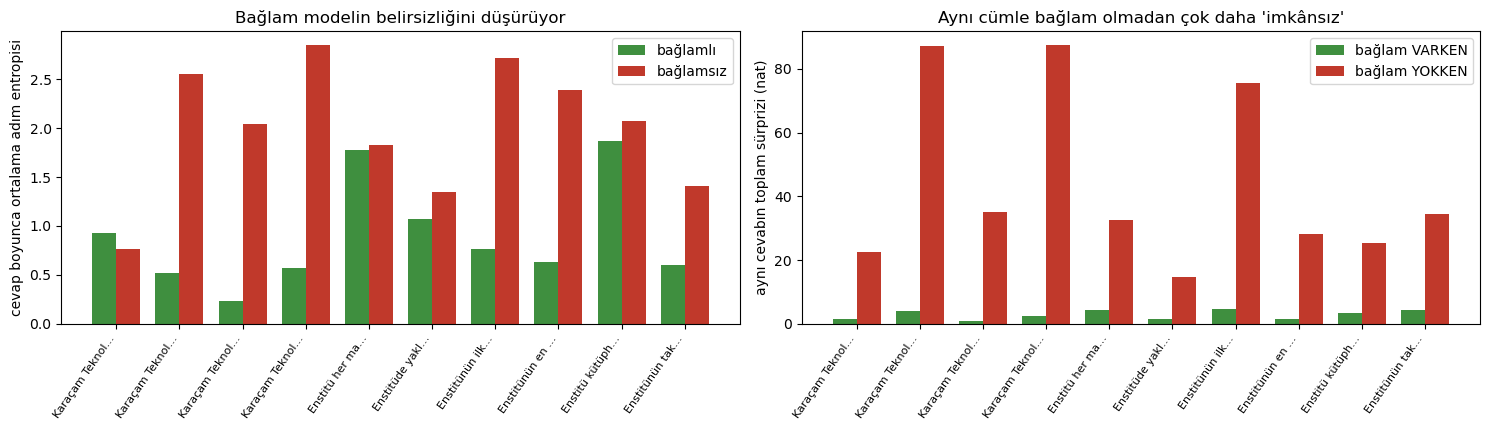

In [23]:
t0 = time.time()
sat = []
for pasaj, anahtar, soru in BILGILER:
    c_b, H_b, id_b = rag_yol(soru, pasaj)            # bağlamlı
    c_s, H_s, id_s = rag_yol(soru, None)             # bağlamsız
    sat.append(dict(soru=soru, anahtar=anahtar, c_b=c_b, c_s=c_s, H_b=np.mean(H_b), H_s=np.mean(H_s),
                    nll_ile=cevap_nll(soru, pasaj, id_b), nll_siz=cevap_nll(soru, None, id_b)))
print(f"({time.time()-t0:.0f} sn)\n")
print(f"{'soru':<44}{'bağlamlı cevap':<34}{'H(bağlamlı)':>12}{'H(bağlamsız)':>14}")
for r in sat:
    print(f"{r['soru'][:42]:<44}{r['c_b'][:32]:<34}{r['H_b']:>12.2f}{r['H_s']:>14.2f}")
print(f"\nortalama adım entropisi: bağlamlı {np.mean([r['H_b'] for r in sat]):.2f} | bağlamsız {np.mean([r['H_s'] for r in sat]):.2f}")
print(f"bağlamlı cevabın toplam sürprizi: bağlam VARKEN {np.mean([r['nll_ile'] for r in sat]):.1f} nat | bağlam YOKKEN {np.mean([r['nll_siz'] for r in sat]):.1f} nat")
print(f"greedy doğruluk: bağlamlı {sum(dogru(r['c_b'], r['anahtar']) for r in sat)}/10 | bağlamsız {sum(dogru(r['c_s'], r['anahtar']) for r in sat)}/10")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4.4))
x = np.arange(len(sat)); w = 0.38
a1.bar(x - w/2, [r["H_b"] for r in sat], w, color="#3f8f3f", label="bağlamlı")
a1.bar(x + w/2, [r["H_s"] for r in sat], w, color="#c0392b", label="bağlamsız")
a1.set_xticks(x); a1.set_xticklabels([b[0][:14] + "…" for b in BILGILER], rotation=55, ha="right", fontsize=8)
a1.set_ylabel("cevap boyunca ortalama adım entropisi"); a1.set_title("Bağlam modelin belirsizliğini düşürüyor"); a1.legend()
a2.bar(x - w/2, [r["nll_ile"] for r in sat], w, color="#3f8f3f", label="bağlam VARKEN")
a2.bar(x + w/2, [r["nll_siz"] for r in sat], w, color="#c0392b", label="bağlam YOKKEN")
a2.set_xticks(x); a2.set_xticklabels([b[0][:14] + "…" for b in BILGILER], rotation=55, ha="right", fontsize=8)
a2.set_ylabel("aynı cevabın toplam sürprizi (nat)"); a2.set_title("Aynı cümle bağlam olmadan çok daha 'imkânsız'"); a2.legend()
plt.tight_layout(); plt.savefig("rag_context_sharpens.png", dpi=130); plt.show()

**Ne gördük?**

- **Bağlam dağılımı sivrileştiriyor:** ortalama adım entropisi bağlamlı **0.90**, bağlamsız **2.00**. 10 sorunun 9'unda bağlamlı daha düşük; en belirgini rektör (0.24 vs 2.05) ve maskot (0.57 vs 2.85) soruları. (`kurulus`'ta ters: bağlamsız model "1987"ye yakın bir yıl tahmini yürütürken emin görünüyor; tek soruda tesadüf olabilir.)
- **Aynı cevap iki dünyada:** bağlamlı üretilen cevabın toplam sürprizi bağlam varken ortalama **2.8 nat**, bağlam yokken **44.3 nat**. Aradaki ~41 nat, olasılık oranı olarak ~10^18 kat. Bağlam, bir cümleyi "imkânsız"dan "olası"ya çeviriyor.
- Greedy doğruluk: bağlamlı **9/10**, bağlamsız **0/10**. (Ölçü kaba: kütüphane sorusunda model `24 saatlerinde` dedi ama `24 saat` geçtiği için doğru sayıldı.)
- Bu, RAG'in teknik özeti: **bağlam bilgiyi vermiyor, bilginin etrafındaki dağılımı sivriltiyor.** Ve dağılım sivriyse, sıcaklığı yükseltmek onu tekrar yayvanlaştırıp hata şansı açıyor (8b).
- **Entropi ücretsiz bir güven sinyali:** bağlamsız cevaplarda belirgin yüksek. Bu, "getirilen belge işe yaradı mı?" sorusunu (Self-RAG/CRAG'in sorusu) modelin kendi çıktısından okumanın bir yolu.

### 8b) Bağlam varken bile sıcaklık doğruluğu çökertir mi?

Her soru (10 tane) için doğru pasaj bağlamda; her ayarda **6 örnek** (greedy'de 1). Doğruluk = cevapta beklenen anahtar kelimenin geçmesi (07'deki ölçü). Ayrıca 7. bölümdeki `yabanci_alfabe` ile kuyruktan gelen **yabancı harf** sızıntısına da bakıyoruz.

Bu hücre bizim 2 çekirdekli CPU'da ~7 dk sürdü (5 sampling ayarı × 10 soru × 6 örnek). Beklerken kahve içebilirsin.

greedy                 doğruluk % 90 | yabancı harf içeren cevap %  0   (5 sn)
T=0.5                  doğruluk % 80 | yabancı harf içeren cevap %  0   (24 sn)
T=1.0                  doğruluk % 47 | yabancı harf içeren cevap % 17   (45 sn)
T=1.5                  doğruluk %  8 | yabancı harf içeren cevap % 87   (66 sn)
T=1.0 + top-p 0.9      doğruluk % 63 | yabancı harf içeren cevap %  3   (91 sn)
T=1.5 + top-p 0.9      doğruluk % 13 | yabancı harf içeren cevap % 82   (118 sn)


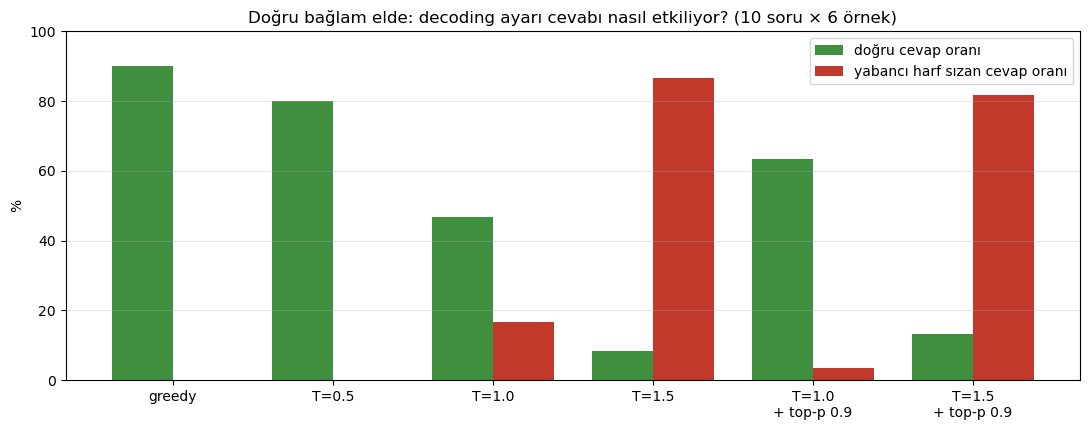

In [24]:
AYARLAR_RAG = [("greedy", dict()),
               ("T=0.5", dict(sample=True, T=0.5)),
               ("T=1.0", dict(sample=True, T=1.0)),
               ("T=1.5", dict(sample=True, T=1.5)),
               ("T=1.0\n+ top-p 0.9", dict(sample=True, T=1.0, top_p=0.9)),
               ("T=1.5\n+ top-p 0.9", dict(sample=True, T=1.5, top_p=0.9))]
RAG_SONUC = {}
t0 = time.time()
for ad, ayar in AYARLAR_RAG:
    dog, yab, ornek_cevaplar = [], [], []
    for i, (pasaj, anahtar, soru) in enumerate(BILGILER):
        cevaplar = rag_uret(soru, pasaj, n=6, seed=i, **ayar)
        dog += [dogru(c, anahtar) for c in cevaplar]
        yab += [yabanci_alfabe(c) > 0 for c in cevaplar]
        ornek_cevaplar.append(cevaplar)
    RAG_SONUC[ad] = dict(dogruluk=float(np.mean(dog)), yabanci=float(np.mean(yab)), cevaplar=ornek_cevaplar)
    print(f"{ad.replace(chr(10), ' '):<22} doğruluk %{100*RAG_SONUC[ad]['dogruluk']:>3.0f} | yabancı harf içeren cevap %{100*RAG_SONUC[ad]['yabanci']:>3.0f}   ({time.time()-t0:.0f} sn)")

fig, ax = plt.subplots(figsize=(11, 4.4))
adlar = list(RAG_SONUC); x = np.arange(len(adlar)); w = 0.38
ax.bar(x - w/2, [100*RAG_SONUC[a]["dogruluk"] for a in adlar], w, color="#3f8f3f", label="doğru cevap oranı")
ax.bar(x + w/2, [100*RAG_SONUC[a]["yabanci"] for a in adlar], w, color="#c0392b", label="yabancı harf sızan cevap oranı")
ax.set_xticks(x); ax.set_xticklabels(adlar); ax.set_ylabel("%"); ax.set_ylim(0, 100)
ax.set_title("Doğru bağlam elde: decoding ayarı cevabı nasıl etkiliyor? (10 soru × 6 örnek)"); ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig("rag_decoding_results.png", dpi=130); plt.show()

**Ne gördük?** (sayılar bizim çalıştırmadan; sende 1-3 puanlık farklar olabilir, sıralama değişmemeli)

- **Doğru pasaj elimizdeyken bile sıcaklık doğruluğu çökertiyor:** greedy **%90**, T=0.5 **%80**, T=1.0 **%47**, T=1.5 **%8**. T=1.0'da cevapların yarısından fazlası yanlış; sebep bilgi eksikliği değil, **zar atılması**.
- **Top-p kurtarıyor (T=1.0'da):** `T=1.0 + top-p 0.9` **%63** (47'den) ve yabancı harf sızıntısı %17'den %3'e düştü. Kuyruğu kesince çöp token'lar seçilemiyor.
- **Ama T=1.5'te top-p işe yaramadı:** `T=1.5 + top-p 0.9` sadece **%13**, yabancı harf %82. Sebep sıra: Hugging Face **önce** sıcaklığı uyguluyor; T=1.5 dağılımı o kadar düzleştiriyor ki %90 kütleye ulaşmak için yüzlerce token (kuyruk dahil) gerekiyor, top-p neredeyse hiç kesmiyor. (5. bölümdeki filtre hattı şemasını hatırla.)
- Pratik sonuç: olgusal RAG cevabında **yaratıcılığa ihtiyaç yok**; greedy veya düşük sıcaklık. Sıcaklığı yükseltiyorsan kuyruğu kesmek **şart**, ve ikisi birbirini dengelemeli.

### 8c) Bağlam yokken örnekler birbirini tutuyor mu?

Aynı soruyu (KTE'nin rektörü) 5 kez, top-p=0.9 ve T=1.0 ile soralım; bir kez **bağlamlı**, bir kez **bağlamsız**. Burada gözümüzle bakacağımız şey: modeli bilgi eksikken **farklı örneklemelerde nasıl davranıyor?** (Bu fikir literatürde SelfCheckGPT'nin temeli: model bir şeyi biliyorsa örnekler birbirini tutar, uyduruyorsa her seferinde başka şey söyler. Egzersiz 5'te sayısal bir ölçüyle deneyeceksin.)

In [25]:
pasaj, anahtar, soru = BILGILER[2]
print("SORU:", soru, "\n")
print("bağlamlı, 5 örnek (T=1.0, top-p 0.9):")
for c in rag_uret(soru, pasaj, n=5, sample=True, T=1.0, top_p=0.9): print("  •", c)
print("\nbağlamsız, 5 örnek (T=1.0, top-p 0.9):")
for c in rag_uret(soru, None, n=5, sample=True, T=1.0, top_p=0.9): print("  •", c)
print("\nbağlamsız, greedy:", rag_uret(soru, None)[0])

SORU: KTE'nin rektörünün adı nedir? 

bağlamlı, 5 örnek (T=1.0, top-p 0.9):
  • Prof. Dr. Aylin Demirtaş
  • Prof. Dr. Aylin Demirtaş.
  • Prof. Dr. Aylin Demirtaş'ı.
  • Prof. Dr. Aylin Demirtaş.
  • Prof. Dr. Aylin Demirtaş.

bağlamsız, 5 örnek (T=1.0, top-p 0.9):
  • Çümü tek veya karmaşık konuda cevap verirseniz, bir haftaya kadar evren
  • Türk Kürt Ejder'in rektörünün adı "Türk Kürtas Ejerder"
  • KTE'nin rektörünün adı "Hamdi Erdem Koca"dir.
  • Kısa ve tek cümle yapmak için, bu durum ve açıklamaları tasarlayabilirsiniz.
  • KTE'nin rektörünün adı dijital sistemiyle conglomorfin olarak bilinen người

bağlamsız, greedy: Kısa ve tek cümleyle cevap verirken, bu sorunun genel cevabı şu


**Ne gördük?**

- **Bağlamlı 5 örnek** noktalama farkları dışında aynı cümle: "Prof. Dr. Aylin Demirtaş". Model biliyor, her çekilişte aynı yere iniyor.
- **Bağlamsız 5 örnek** her biri başka: `Hamdi Erdem Koca`, `Türk Kürtas Ejerder`, sistem talimatını tekrar eden cümleler, bir tanesi Vietnamca karakterlerle bitiyor. Model **bilmiyor ve her çekilişte başka bir şey uyduruyor**.
- Bağlamsız **greedy** ise tek bir cevap veriyor ("Kısa ve tek cümleyle cevap verirken..."), kendinden emin ve sakin; hiç "bilmiyorum" demiyor. Tutarsızlık, **ancak örnekleyince** ortaya çıkıyor. Bu, SelfCheckGPT'nin temel fikri: halüsinasyonu tek bir cevaba bakarak değil, **birkaç örneğin birbirini tutup tutmamasına** bakarak yakalamak.
- Bu iki satır gözlem sayısal bir kanıt değil; Egzersiz 5'te ölçeceksin.

### 8d) Tuzak: `repetition_penalty` RAG'de neden tehlikeli?

Bölüm 6'da tekrar cezasını tekrar döngüsünü kırmak için kullandık. Ama RAG'de **doğru cevap çoğu zaman bağlamdaki kelimelerin kopyası** ("Aylin Demirtaş" pasajda geçiyor, cevapta da geçmeli). Ceza, prompt'ta geçen token'ları da cezalandırıyor. Greedy okuyucuyla, doğru bağlam elde, sadece `repetition_penalty`'yi değiştirelim.

Bir not: `1.1` değeri Qwen Instruct'ın `generation_config`'inde **gizlice** duran varsayılan. 07'deki `sohbet()` fonksiyonu `do_sample=False` yazmasına rağmen bu cezayı uyguluyordu; bu notebook'ta ceza `rep=1.0` ile açıkça kapalı.

In [26]:
print(f"{'repetition_penalty':<20}{'doğru (10 soru, greedy)':>26}   örnek cevap (rektör sorusu)")
REP_SONUC = {}
for rep in [1.0, 1.1, 1.3, 2.0]:
    dog = 0; ornek = ""
    for i, (pasaj, anahtar, soru) in enumerate(BILGILER):
        c = rag_uret(soru, pasaj, rep=rep)[0]
        dog += dogru(c, anahtar)
        if i == 2: ornek = c
    REP_SONUC[rep] = dog
    print(f"{rep:<20}{dog:>22}/10   {ornek[:70]!r}")

repetition_penalty     doğru (10 soru, greedy)   örnek cevap (rektör sorusu)
1.0                                      9/10   'Prof. Dr. Aylin Demirtaş.'
1.1                                      7/10   'Prof. Dr. Aylin Demirtaş.'
1.3                                      2/10   'Prof. Dr. Aylin Demirtaş.'
2.0                                      0/10   'Profdrayalindemiltastaorthyerlikten sonra geldiğini belirlenmektediri.'


**Ne gördük?**

- **`repetition_penalty` arttıkça doğruluk çöküyor:** 1.0 → **9/10**, 1.1 → **7/10**, 1.3 → **2/10**, 2.0 → **0/10**. 2.0'da model "Aylin Demirtaş"ı bile bozuyor (`Profdrayalindemiltastaorthyerlikten...`): doğru cevap bağlamdaki kelimelerin kopyası ve ceza prompt'taki token'ları da cezalandırıyor.
- **1.1, Qwen Instruct'ın gizli varsayılanı.** 07'deki `sohbet()` `do_sample=False` yazmasına rağmen bu cezayı uyguluyordu; yani 07'de "okuyucu hatası" dediğimiz hataların bir kısmı bu gizli ayardan gelmiş olabilir (aynı koşulda ölçmedik; 9/10 → 7/10 farkı küçük değil).
- Ders: **RAG okuyucusunda `repetition_penalty` 1.0 olmalı.** Tekrar cezası, kopyalanması gereken olgular için bir tuzak.

### Karar rehberi

| Strateji | Ne yapar | İyi olduğu yer | Tuzağı | RAG okuyucusu için |
|---|---|---|---|---|
| **Greedy** | her adımda en olası token | kısa, olgusal, tekrarlanabilir çıktı | uzun metinde tekrar döngüsü | **varsayılan iyi seçim** (8b: %90) |
| **Beam search** | k yarım rotayı sürdür, toplam olasılığı en yüksek olanı seç | girdiye sıkı bağlı işler (HF dokümantasyonu: altyazı üretme, konuşma tanıma) | açık uçlu metinde tekrar/sıkıcılık, k kat pahalı, k büyütmek garantili iyileştirme değil | genellikle gereksiz |
| **Temperature** | dağılımı sivrilt (T<1) ya da düzleştir (T>1) | çeşitliliği tek düğmeyle ayarlamak | kuyruğu kesmez; T>1'de çöp artar | düşük (0-0.3) |
| **Top-k** | en olası k token'ı tut | basit ve hızlı | k sabit: sivri dağılımda fazla, yayvanda az | gerek yok |
| **Top-p** | toplamı p'ye ulaşana kadar tut | aday sayısı dağılıma uyuyor | yüksek T ile kuyruğu yeterince kesmeyebilir (8b) | T yükseltiyorsan şart |
| **Min-p** | en olası token'ın p katından küçükleri at | dağılıma uyan alternatif (Egzersiz 3) | — | — |
| **Tekrar cezası** | geçmiş token'ları cezalandır | semptom bastırma | metni bozar; **RAG'de olgu kopyalamayı engeller** (8d) | **kapalı (1.0)** |

**Bu deneylerden çıkan pratik kural:** Kısa/olgusal cevap (RAG okuyucusu): greedy ya da T ≤ 0.3. Yaratıcı veya uzun metin: T≈0.7 + top-p≈0.9 civarı bir başlangıç noktası, sonra metne bakarak ayarla. Sıcaklığı yükseltiyorsan kuyruğu kesmeyi unutma. Decoding **bilgi katmaz**: modelin bilmediği şeyi (Türkçe, KTE'nin rektörü) bilmez hale getirmez de, bilir hale getirmez de.

**Tekrarlanabilirlik notu:** Greedy/T=0 çoğu zaman aynı sonucu verir ama **her zaman değil**: Atil ve ark. (2024) "deterministik" ayarlara rağmen çıktıların çalıştırmalar arasında değişebildiğini gösterdi (kaynaklara bak). Bu notebook'ta tek süreçte, CPU'da, sabit tohumla çalıştığımız için birebir tekrar ediyor.

**Tez bağlantısı (ilk fikir, kesin değil):**

- **#2 (LLM ajanlarında aynı görevin tekrarlı koşullarda değişkenliği):** değişkenliğin ana kaynaklarından biri bu notebook'un konusu, decoding rastgeleliği. 8b (sıcaklığa göre doğruluk) ve 8c (örnekler arası tutarlılık) bu değişkenliği ölçmenin minyatür hali.
- **#7 (Self-RAG/CRAG erişim kalitesi denetimi) ve #1 (güvenilirlik damgalı brifing):** entropi (8a) ve örnekler arası tutarlılık (8c, Egzersiz 5) "bu cevaba güven" kararı için **ücretsiz sinyaller**.
- **#15 (Türkçe RAG asistanı):** Türkçe'de kuyruk sızıntısı (7. bölüm) ve gizli `repetition_penalty` (8d) bir asistan kurarken ayarlanması gereken mühendislik ayrıntıları.

## 9) Özet

- **Model token seçmez, olasılık verir; decoding o olasılıktan birini seçme kuralıdır.** Ağırlıklara dokunmadan çıktıyı kökten değiştirir. Hugging Face'te `do_sample=True` aslında `top_k=50` sampling; model paketindeki gizli ayarlar (Instruct'ın `repetition_penalty=1.1`'i) sessizce uygulanır.
- **Greedy** hızlı ve tekrarlanabilir ama uzun metinde **kısır döngüye** giriyor (tekrardan sonra seçilen token'ın olasılığı 0.33 → 0.63, sona doğru ~1.0).
- **Beam search** greedy'nin bulamadığı çok daha olası cümleyi buluyor (−79 → ≈−60) ama **en olası metin iyi metin değil**: kendini tekrar ediyor. İnsan metni beam'den ~9 kat sürprizli (2.45 vs 0.26 nat/token).
- **Sampling + temperature:** çeşitlilik getirir, tekrarı bitirir, ama sıcaklık arttıkça akıcılık çöker (hakem bpc 0.63 → 2.55). Temperature kuyruğu **kesmez**.
- **Top-k / top-p kuyruğu kesiyor.** Kuyruk ağır: top-50'nin dışında ortalama %21 kütle. Top-p aday sayısını dağılıma göre ayarlıyor (1 ile 14.394 arasında); sabit k iki yönde de yanlış. Türkçe'de saf T=1'de 10 örneğin 7'sinde yabancı alfabe sızıyor; kuyruğu kesince 0-1'e iniyor. Ama kuyruk kesmek **modelin bilgisini artırmaz**.
- **RAG'le bağlantı:** Bağlam, cevabın etrafındaki dağılımı **sivriltiyor** (entropi 2.00 → 0.90; aynı cevabın sürprizi 44 → 3 nat). Doğru bağlam elde bile sıcaklık doğruluğu %90'dan %8'e indiriyor; top-p T=1'de kurtarıyor (%47 → %63) ama T=1.5'te yetmiyor (sıra: önce sıcaklık). `repetition_penalty` RAG'de olgu kopyalamayı bozuyor (9/10 → 7/10 → 0/10).
- **Tutarlılık bir güven sinyali:** bilgiyi biliyorsa örnekler birbirini tutuyor, uyduruyorsa dağılıyor (SelfCheckGPT fikri).

**Sırada:** Faz 1 bitti. `RAG-Systems-lab/01_vector_search_embeddings`: bu notebook'ta bulucuyu hatasız varsaydık (doğru pasajı elle verdik); gerçek bir RAG'de önce **doğru pasajı bulmak** gerekiyor.

## Egzersizler

Çözümler verilmiyor. Her egzersizin altında bir kod hücresi var ve içinde **TODO** adımları yazılı: TODO'ları sırayla doldur, hücreyi çalıştır, sonucu yorumla. Bu sefer de egzersizlerin çoğu **model kullanımı**: modeli çalıştır, ölç, karşılaştır. Her egzersizde **önce tahminini yaz** (yorum satırı olarak bile olur), sonra ölç; tahmin ile ölçümün ayrıldığı yerler öğrenmenin olduğu yerler.

**Değişken adı uyarısı:** `gpt`, `tok_gpt`, `qwen_base`, `tok_q`, `qwen_inst`, `tok_qi`, `PROMPT`, `PROMPT_TR`, `P_INSAN`, `INSAN`, `BILGILER`, `SONUC_KAL`, `RAG_SONUC` ve fonksiyonlar (`kutu`, `ok_ciz`, `sonraki_dagilim`, `entropi`, `en_olasilar`, `uret`, `kume`, `kosu`, `tekrar_orani`, `cesitlilik`, `devam_nll`, `hakem_bpc`, `degerlendir`, `filtrele`, `yabanci_alfabe`, `rag_uret`, `dogru`) global. Egzersizlerde bunları **ezme** (`m_ex`, `sonuc_ex`, `r_ex` gibi farklı isimler kullan). `SONUC_KAL` 5. bölümün grafiği için kullanılıyor: egzersizlerde `kosu()` yerine `kume()` + `degerlendir()` kullanırsan ona karışmazsın.

**Süre uyarısı:** Sampling içeren döngüler hızlı büyür (ızgara × örnek sayısı × token). Önce küçük çalıştır (`n=2`, `n_token=30`), doğru çalışınca büyüt.

**Bellek uyarısı:** Yeni bir model yüklersen (E5'in isteğe bağlı adımı) işin bitince `del m_ex; gc.collect()` yap.

### Egzersiz 1 — Dağılımı oku: entropi ve çekirdek boyutu

Şu 6 prompt'u (veya kendi seçtiklerini) iki modele, `gpt` ve `qwen_base`'e ver: olgusal (`"Water boils at 100 degrees"`, `"The capital of Japan is"`), açık uçlu (`"My favorite color is"`, `"Once upon a time"`), Türkçe (`"Türkiye'nin başkenti"`, `"Bir zamanlar"`).

(a) **Yazmadan önce tahmin et:** hangi prompt/model çifti en yüksek entropiye sahip olur? Qwen'in Türkçe prompt'lardaki entropisi İngilizce olgusal prompt'lardan yüksek mi?
(b) Her çift için **entropi**, **en olası token'ın olasılığı** ve **p=0.9 çekirdeğinin boyutu** (kaç token) tablosu.
(c) Entropi (x) – çekirdek boyutu (y, log ölçek) dağılım grafiği. İlişki ne?
(d) En yüksek entropili prompt için 5. bölümdeki kuyruk hesabını yap: top-50'nin dışında kalan kütle ne, 20 adımda en az bir kez kuyruktan çekme olasılığı ne?
(e) Büyük model (Qwen) aynı prompt'larda GPT-2'den daha sivri mi? (Dikkat: tokenizer'lar farklı; entropi token başına.)


==== Egzersiz 1: Dağılımı oku — entropi ve çekirdek boyutu ====
GPT-2  | Water boils at 100 degrees     | olgusal    | Entropi: 2.9023 | Nucleus boyutu: 20
GPT-2  | The capital of Japan is        | olgusal    | Entropi: 5.6527 | Nucleus boyutu: 1115
GPT-2  | My favorite color is           | açık uçlu  | Entropi: 5.8131 | Nucleus boyutu: 1682
GPT-2  | Once upon a time               | açık uçlu  | Entropi: 3.6118 | Nucleus boyutu: 228
GPT-2  | Türkiye'nin başkenti           | olgusal    | Entropi: 5.5078 | Nucleus boyutu: 850
GPT-2  | Bir zamanlar                   | açık uçlu  | Entropi: 6.4526 | Nucleus boyutu: 2471
Qwen   | Water boils at 100 degrees     | olgusal    | Entropi: 1.6157 | Nucleus boyutu: 7
Qwen   | The capital of Japan is        | olgusal    | Entropi: 3.8047 | Nucleus boyutu: 85
Qwen   | My favorite color is           | açık uçlu  | Entropi: 3.9518 | Nucleus boyutu: 99
Qwen   | Once upon a time               | açık uçlu  | Entropi: 2.2594 | Nucleus boyutu: 10
Qwen   |

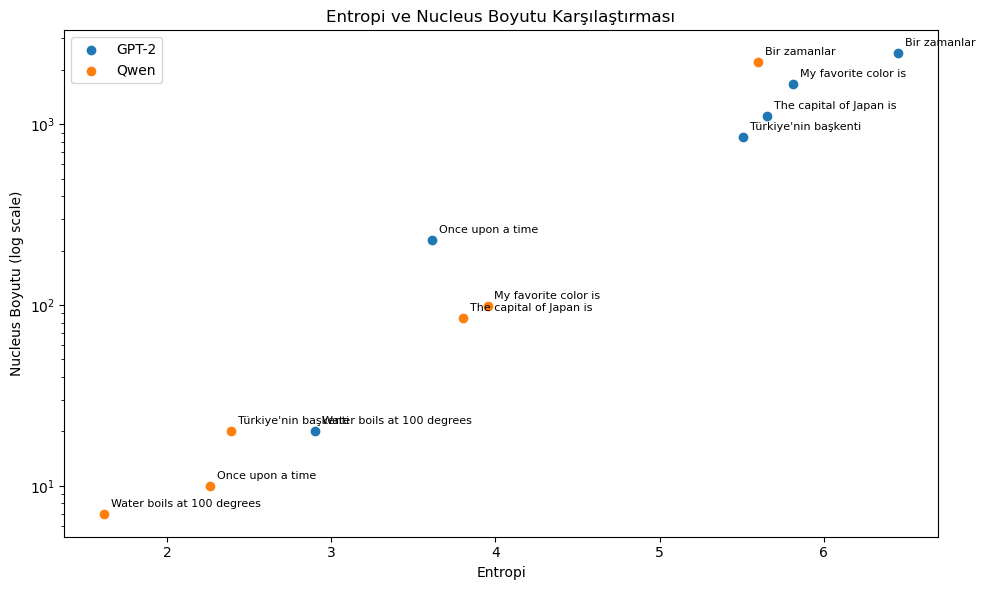

In [ ]:
print("\n==== Egzersiz 1: Dağılımı oku — entropi ve çekirdek boyutu ====")
# TODO 1: önce (a) tahminini bir yorum satırı olarak yaz
# TODO 2: PROMPTLAR = [("Water boils at 100 degrees", "olgusal"), ...]   # 6 prompt: 2 olgusal, 2 açık uçlu, 2 Türkçe
# TODO 3: for (model, tok, ad) in [(gpt, tok_gpt, "GPT-2"), (qwen_base, tok_q, "Qwen")]: for prompt in PROMPTLAR:
#             p = sonraki_dagilim(model, tok, prompt)
#             entropi(p), p.max().item(), nucleus boyutu: s, _ = torch.sort(p, descending=True); int((torch.cumsum(s, 0) < 0.9).sum()) + 1
# TODO 4: sonuçları hizalı bir tablo olarak yazdır (b)
# TODO 5: entropi - nucleus boyutu scatter'ı (y ekseni log), noktaları prompt adıyla etiketle (c)
# TODO 6: en yüksek entropili çift için top-50 dışı kütle: 1 - torch.topk(p, 50).values.sum(); sonra 1 - (1 - kuyruk)**20 (d)
# TODO 7: GPT-2 ile Qwen'in aynı prompt'lardaki entropilerini karşılaştır ve tek cümleyle yorumla (e)

# Tahmin A: GPT-2 Türkçe ve açık uçlu promptlarda daha yüksek entropi ve nucleus boyutu gösterecek, Qwen ise olgusal promptlarda daha düşük entropi ve nucleus boyutu gösterecek. Ayrıca Qwen Türkçe prompt entropisi ingilizceye göre yakın olacak.

PROMPTLAR = [
    ("Water boils at 100 degrees", "olgusal"),
    ("The capital of Japan is", "olgusal"),
    ("My favorite color is", "açık uçlu"),
    ("Once upon a time", "açık uçlu"),
    ("Türkiye'nin başkenti", "olgusal"),
    ("Bir zamanlar", "açık uçlu")
]

for (model, tok, ad) in [(gpt, tok_gpt, "GPT-2"), (qwen_base, tok_q, "Qwen")]:
    for prompt, tur in PROMPTLAR:
        p = sonraki_dagilim(model, tok, prompt)
        ent = entropi(p)
        s, _ = torch.sort(p, descending=True)
        n90 = int((torch.cumsum(s, 0) < 0.9).sum()) + 1
        print(f"{ad:<6} | {prompt:<30} | {tur:<10} | Entropi: {ent:.4f} | Nucleus boyutu: {n90}")

# Entropi ve nucleus boyutu scatter plot
fig, ax = plt.subplots(figsize=(10, 6))
for (model, tok, ad) in [(gpt, tok_gpt, "GPT-2"), (qwen_base, tok_q, "Qwen")]:
    entropies = []
    nucleus_sizes = []
    for prompt, tur in PROMPTLAR:
        p = sonraki_dagilim(model, tok, prompt)
        entropies.append(entropi(p))
        s, _ = torch.sort(p, descending=True)
        nucleus_sizes.append(int((torch.cumsum(s, 0) < 0.9).sum()) + 1)
    ax.scatter(entropies, nucleus_sizes, label=ad)
    for i, prompt in enumerate(PROMPTLAR):
        ax.annotate(prompt[0], (entropies[i], nucleus_sizes[i]), textcoords="offset points", xytext=(5, 5), fontsize=8)
ax.set_xlabel("Entropi")
ax.set_ylabel("Nucleus Boyutu (log scale)")
ax.set_yscale("log")
ax.set_title("Entropi ve Nucleus Boyutu Karşılaştırması")
ax.legend()
plt.tight_layout()
plt.savefig("entropy_nucleus_comparison.png", dpi=130)

# Top-50 dışı kütle ve 20 adımda çekilme olasılığı
for (model, tok, ad) in [(gpt, tok_gpt, "GPT-2"), (qwen_base, tok_q, "Qwen")]:
    for prompt, tur in PROMPTLAR:
        p = sonraki_dagilim(model, tok, prompt)
        top_50_mass = torch.topk(p, 50).values.sum().item()
        tail_mass = 1 - top_50_mass
        prob_tail_in_20_steps = 1 - (1 - tail_mass) ** 20
        print(f"{ad:<6} | {prompt:<30} | {tur:<10} | Top-50 dışı kütle: {tail_mass:.4f} | 20 adımda çekilme olasılığı: {prob_tail_in_20_steps:.4f}")

# Grafiğe bakıldığında, Entropi ile Nucleus arasında pozitif bir ilişki gözlemlenmektedir. Entropi arttıkça Nucleus'a giren kelime sayısı da artmaktadır.
# Qwen, olgusal promptlarda GPT-2'ye göre daha az entropi ve nucleus boyutu gösteriyor (örn. Water boils: 1.62 vs 2.90).
# Açık uçlu promptlarda da aynı yönde (Once upon a time: 2.26 vs 3.61).
# Türkçede Qwen yine daha düşük entropili (Türkiye'nin başkenti: 2.39 vs 5.51) ama "Bir zamanlar" Qwen'de de yüksek (5.60, nucleus 2212). Düşük entropi "daha iyi performans" demek değil, sadece model daha emin.
# Beklenmeyen: "olgusal" etiketi düşük entropi getirmedi. "The capital of Japan is" GPT-2'de 5.65 (nucleus 1115): cevap formatı belli olmadığı için olasılık " Tokyo", " a", " the" gibi çok devama dağılıyor. Entropiyi belirleyen şey sorunun türü değil, prompt'un devamı ne kadar zorluyor olması.


### Egzersiz 2 — Sıcaklık × top-p ızgarası

Kendi İngilizce prompt'unu seç (bir haber başlangıcı, bir hikâye, bir tarif...). `T ∈ {0.3, 0.7, 1.0, 1.3}` ve `top_p ∈ {0.5, 0.9, 1.0}` ızgarasının 12 hücresinin her birinde `gpt` ile 6 örnek üret ve `degerlendir` ile ölç.

(a) **Önce tahmin et:** hangi hücre en iyi denge? Sıcaklık mı top-p mi daha etkili?
(b) `tekrar`, `cesit` ve `bpc` için üç ısı haritası (hücrelerin içine sayıyı yaz).
(c) Kendi "kabul edilebilir" bölgeni tanımla (ör. `tekrar < 0.1` ve `bpc` senin seçtiğin bir eşiğin altında) ve haritada işaretle. Bölgenin şekli ne? Top-p düşükken sıcaklık daha yükseğe çıkabiliyor mu?
(d) Aynı ızgarayı **Türkçe** bir prompt ve `qwen_base` ile tekrarla (7. bölümdeki `yabanci_alfabe` ile birlikte). Kabul edilebilir bölge daralıyor mu? (Not: burada üreten de hakem de Qwen olur: bu ölçümü nasıl etkiler?)
(e) Tek bir "tatlı nokta" seç. Hangi durumda (olgusal RAG cevabı mı, yaratıcı yazı mı) onu değiştirirsin?


==== Egzersiz 2: Sıcaklık × top-p ızgarası ====


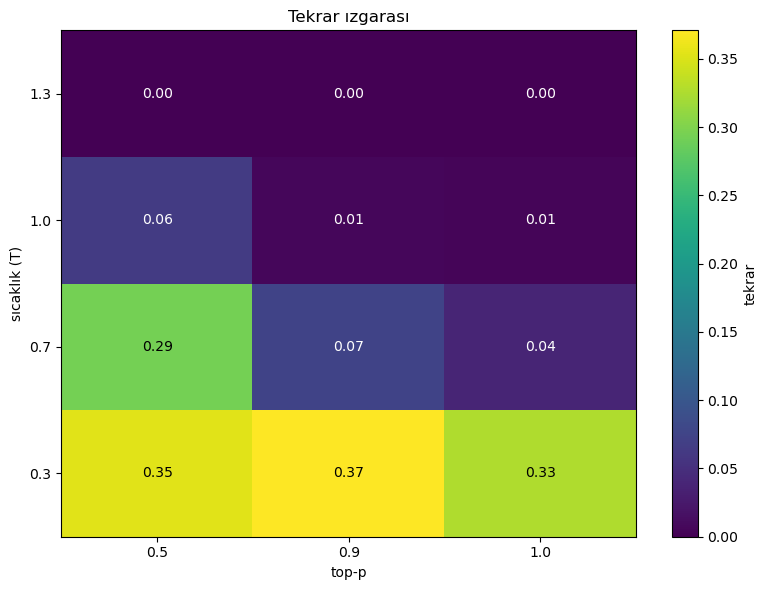

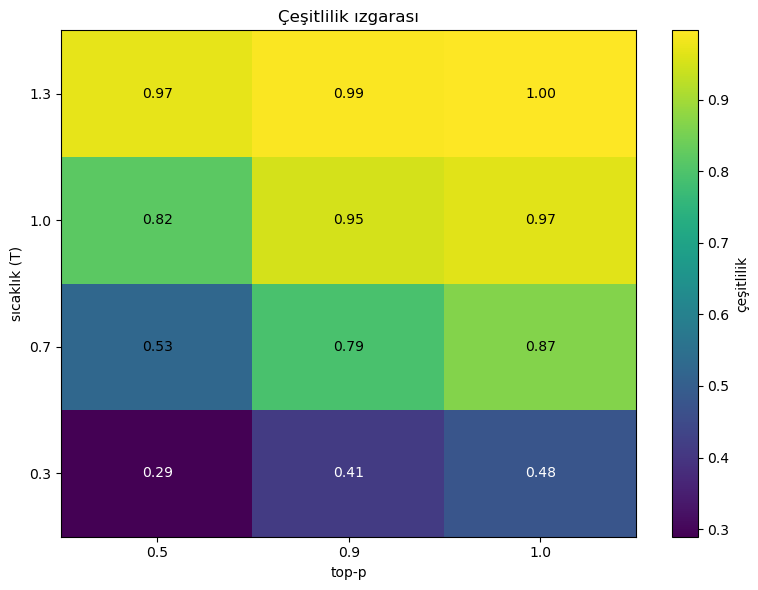

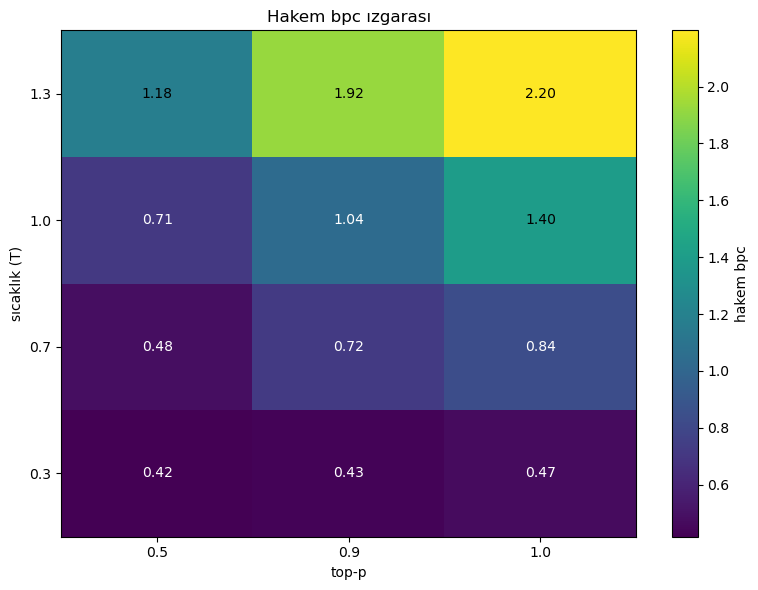

In [ ]:
print("\n==== Egzersiz 2: Sıcaklık × top-p ızgarası ====")
# TODO 1: önce (a) tahminini yaz
# TODO 2: PROMPT_EX = "..."   # kendi İngilizce prompt'un
# TODO 3: SICAKLIKLAR = [0.3, 0.7, 1.0, 1.3]; TOPP = [0.5, 0.9, 1.0]
# TODO 4: iç içe döngü: metinler, _ = kume(gpt, tok_gpt, PROMPT_EX, n=6, n_token=50, sample=True, T=T, top_p=p)
#         r = degerlendir(PROMPT_EX, metinler)      # (SONUC_KAL'ı kirletmemek için kosu() değil kume() + degerlendir())
# TODO 5: r["tekrar"], r["cesit"], r["bpc"] için 3 ısı haritası (plt.imshow + hücre içine sayı)  (b)
# TODO 6: "kabul edilebilir" bölgeyi tanımla ve işaretle (c)

# Tahmin A: Sıcaklık arttıkça modelin özgürlüğü artacağı için çok fazla kafası karışacak ama tekrar oranı da bi o kadar düşecektir. Bu kısımda engellemek için top-p değeri ortaya çıkacak ama çok düşük top-p değeri de çeşitliliği düşürecektir. Bu yüzden orta seviyede bir sıcaklık ve top-p değeri en iyi sonucu verecektir. (T=0.7, top-p=0.9 gibi)

PROMPT_EX = [
    ("Donald Trump was raised tariffs on Chinese imports, which led to a trade war."),
    ("Serbian prime minister Ana Brnabić announced new economic reforms to boost the country's growth."),
    ("The Brazil Presidental Elections was started in October 2026."),
    ("The capital of Albania is Tirana"),
    ("The Eiffel Tower is one of the most famous landmarks in Paris, France."),
    ("Once upon a time, there was a man"),
    ("My favorite weekend activity is"),
    ("What is the capital of France?"),
    ("Capitalism is a"),
    ("Communism is a")
]

SICAKLIKLAR = [0.3, 0.7, 1.0, 1.3]; TOPP = [0.5, 0.9, 1.0]

grid_shape = (len(SICAKLIKLAR), len(TOPP))
matris_tekrar = np.zeros(grid_shape); matris_cesit = np.zeros(grid_shape); matris_bpc = np.zeros(grid_shape)

for i, T in enumerate(SICAKLIKLAR):
    for j, p in enumerate(TOPP):
        tekrar, cesit, bpc = [], [], []
        for prompt in PROMPT_EX:
            metinler, _ = kume(gpt, tok_gpt, prompt, n=6, n_token=50, sample=True, T=T, top_p=p)
            r = degerlendir(prompt, metinler)
            tekrar.append(r["tekrar"]); cesit.append(r["cesit"]); bpc.append(r["bpc"])
        matris_tekrar[i, j] = np.mean(tekrar); matris_cesit[i, j] = np.mean(cesit); matris_bpc[i, j] = np.mean(bpc)

metrikler = [("tekrar", matris_tekrar), ("çeşitlilik", matris_cesit), ("hakem bpc", matris_bpc)]
for metrik_ad, matris in metrikler:
    fig, ax = plt.subplots(figsize=(8, 6))
    cax = ax.imshow(matris, cmap="viridis", origin="lower", aspect="auto")
    ax.set_xticks(np.arange(len(TOPP))); ax.set_yticks(np.arange(len(SICAKLIKLAR)))
    ax.set_xticklabels(TOPP); ax.set_yticklabels(SICAKLIKLAR)
    ax.set_xlabel("top-p"); ax.set_ylabel("sıcaklık (T)")
    ax.set_title(f"{metrik_ad.capitalize()} ızgarası")
    for i in range(len(SICAKLIKLAR)):
        for j in range(len(TOPP)):
            text = f"{matris[i, j]:.2f}"
            ax.text(j, i, text, ha="center", va="center", color="w" if matris[i, j] < matris.max()/2 else "black")
    fig.colorbar(cax, label=metrik_ad)
    plt.tight_layout(); plt.savefig(f"{metrik_ad}_grid.png", dpi=130); plt.show()

# Isı haritalarına baktığımızda tekrar anlamında sıcaklık arttıkça tekrar oranının düştüğünü görüyoruz. Top-p'de ise herhangi bir artış veya azalış örüntüsü yok.
# Sıcaklık aynı zamanda arttıkça çeşitlilik artıyor. Top-p'de ise çeşitlilik arttıkça tekrar oranı artıyor. Hakem bpc açısından baktığımızda sıcaklık arttıkça bpc artıyor, top-p'de ise hafif bir artış söz konusu diyebiliriz.

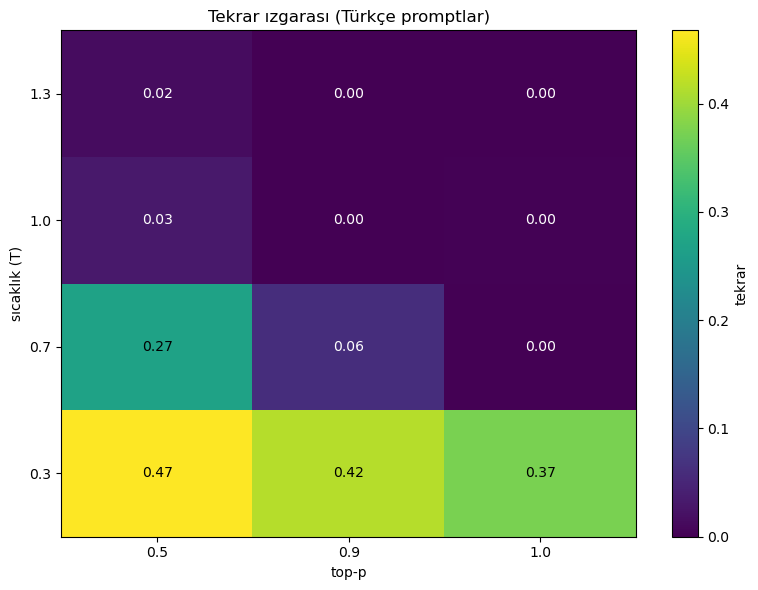

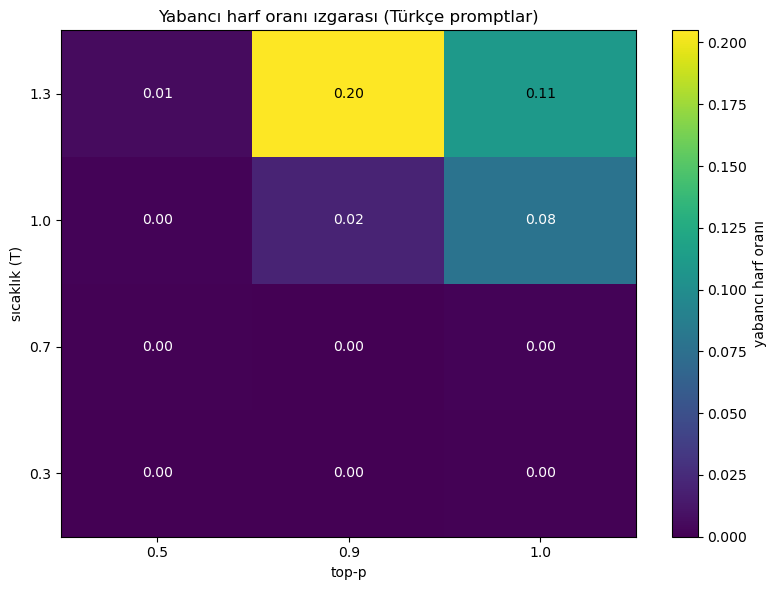

In [62]:
# TODO 7: aynı ızgara, Türkçe prompt + kume(qwen_base, tok_q, ...) ; yabanci_alfabe oranını da ekle (d)
# TODO 8: tek bir "tatlı nokta" seç ve ne zaman değiştirmen gerektiğini iki cümleyle yaz (e)

TURKCE_PROMPTLAR = [
    "Bir zamanlar uzaklarda",
    "Türkiye'nin başkenti",
    "En sevdiğim renk"
]

matris_tr_tekrar = np.zeros(grid_shape); matris_tr_yabanci = np.zeros(grid_shape)
for i, T in enumerate(SICAKLIKLAR):
    for j, p in enumerate(TOPP):
        tekrar, cesit, yabanci = [], [], []
        for prompt in TURKCE_PROMPTLAR:
            metinler, _ = kume(qwen_base, tok_q, prompt, n=6, n_token=50, sample=True, T=T, top_p=p)
            tekrar.append(np.mean([tekrar_orani(m) for m in metinler]))
            yabanci.append(np.mean([yabanci_alfabe(m) for m in metinler]))
        matris_tr_tekrar[i, j] = np.mean(tekrar); matris_tr_yabanci[i, j] = np.mean(yabanci)

for metrik_ad, matris in [("tekrar", matris_tr_tekrar), ("yabancı harf oranı", matris_tr_yabanci)]:
    fig, ax = plt.subplots(figsize=(8, 6))
    cax = ax.imshow(matris, cmap="viridis", origin="lower", aspect="auto")
    ax.set_xticks(np.arange(len(TOPP))); ax.set_yticks(np.arange(len(SICAKLIKLAR)))
    ax.set_xticklabels(TOPP); ax.set_yticklabels(SICAKLIKLAR)
    ax.set_xlabel("top-p"); ax.set_ylabel("sıcaklık (T)")
    ax.set_title(f"{metrik_ad.capitalize()} ızgarası (Türkçe promptlar)")
    for i in range(len(SICAKLIKLAR)):
        for j in range(len(TOPP)):
            text = f"{matris[i, j]:.2f}"
            ax.text(j, i, text, ha="center", va="center", color="w" if matris[i, j] < matris.max()/2 else "black")
    fig.colorbar(cax, label=metrik_ad)
    plt.tight_layout(); plt.savefig(f"tr_{metrik_ad}_grid.png", dpi=130); plt.show()

### Egzersiz 3 — Min-p'yi elle yaz

**Min-p** (Nguyen ve ark. 2024) top-p'nin bir alternatifi: en olası token'ın olasılığının `min_p` katından **küçük** olan token'ları at. Örneğin `min_p=0.1` ve en olası token %50 ise, %5'ten küçük her token atılır; en olası token %10 ise (yayvan dağılım), %1'den küçükler atılır. Eşik dağılıma göre kendiliğinden ayarlanıyor.

(a) `min_p_filtrele(logits, min_p)` fonksiyonunu yaz (5. bölümdeki `filtrele` gibi, atılan token'lar `-inf`).
(b) Hugging Face'in `MinPLogitsWarper`'ı ile aynı token'ları tutuyor mu?
(c) 1. bölümdeki üç dağılım için (sivri `"Water boils at 100 degrees"`, orta `"The meaning of life is"`, yayvan `"Once upon a time, there was a"`) `min_p=0.05`, `min_p=0.1` ve `top_p=0.9`'un **kaç token tuttuğunu** tablo yap.
(d) Hangisi yayvan dağılımda daha cömert, sivri dağılımda daha sıkı? Kuyruk kesmek açısından hangisini daha mantıklı buluyorsun?
(e) `min_p=0.1` ile unicorn prompt'undan 8 örnek üret ve `degerlendir` ile 5. bölümdeki tabloya ekle.

In [63]:
print("\n==== Egzersiz 3: Min-p'yi elle yaz ====")
from transformers import MinPLogitsWarper

def min_p_filtrele(logits, min_p=0.1):
    # TODO 1: logits'in kopyasını al; p = torch.softmax(logits, -1); esik = min_p * p.max()
    #         p < esik olan token'ların logit'ini -inf yap ve kopyayı döndür

    logits_copy = logits.clone()  # logits'in kopyasını al
    p = torch.softmax(logits_copy, dim=-1)  # logits'ten olasılıkları hesapla
    esik = min_p * p.max()  # eşik

    under_esik_mask = p < esik  # eşikten küçük olanları bul
    logits_copy[under_esik_mask] = float('-inf')  # eşikten küçük olanların logit'ini -inf yap
    return logits_copy  # kopyayı döndür

PROMPTLAR_EX3 = [
    "Water boils at 100 degrees",
    "The meaning of life is",
    "Once upon a time, there was a",
]

def sonraki_dagilim_soft_max(model, tok, prompt, return_logits=False):
    """prompt'un son konumundaki logit'leri döndürür (softmax'tan önce)"""
    ids = tok(prompt, return_tensors="pt")
    out = model.generate(**ids, max_new_tokens=1, do_sample=False, output_scores=True, return_dict_in_generate=True)
    logits = out.scores[0][0]  # (vocab_size,)
    if return_logits:
        return logits
    else:
        return torch.softmax(logits, dim=-1)

lg = sonraki_dagilim_soft_max(gpt, tok_gpt, PROMPTLAR_EX3[0], return_logits=True)

warper = MinPLogitsWarper(min_p=0.1)
huggingface_logits = warper(None, lg.unsqueeze(0).clone())[0]

my_filter = torch.isfinite(min_p_filtrele(lg, 0.1))
hf_filter = torch.isfinite(huggingface_logits)

is_eq = torch.equal(my_filter, hf_filter)
print(f"MinPLogitsWarper ile min_p_filtrele eşit mi? {is_eq}")

print(f"\n{'Prompt':<30} | {'min_p=0.05':<12} | {'min_p=0.1':<12} | {'top_p=0.9':<12}")
print("-" * 75)

prompt_results = {}
for prompt in PROMPTLAR_EX3:
    lg = sonraki_dagilim_soft_max(gpt, tok_gpt, prompt, return_logits=True)
    
    # min_p = 0.05
    lg_05 = min_p_filtrele(lg, min_p=0.05)
    kept_05 = torch.isfinite(lg_05).sum().item()
    
    # min_p = 0.1
    lg_10 = min_p_filtrele(lg, min_p=0.1)
    kept_10 = torch.isfinite(lg_10).sum().item()
    
    # top_p = 0.9 (Nucleus boyutu)
    p = torch.softmax(lg, dim=-1)
    s, _ = torch.sort(p, descending=True)
    n90 = int((torch.cumsum(s, 0) < 0.9).sum()) + 1
    
    print(f"{prompt[:28]+'...':<30} | {kept_05:<12} | {kept_10:<12} | {n90:<12}")

UNICORN_PROMPT = "In a shocking finding, scientists discovered a herd of unicorns living in a remote valley in the Andes."

print(f"\n\n{'Prompt':<30} | {'Metot':<25} | {'Tekrar Oranı':>15} | {'Çeşitlilik':>15} | {'Hakem BPC':>15}")
print("-" * 73)

metinler, _ = uret(gpt, tok_gpt, UNICORN_PROMPT, n=8, sample=True, top_k=0, top_p=1.0, min_p=0.1)
skorlar = degerlendir(UNICORN_PROMPT, metinler)
SONUC_KAL[f"min-p 0.1 ({UNICORN_PROMPT})"] = skorlar
print(f"{UNICORN_PROMPT[:28]+'...':<30} | {'min-p 0.1':<25} | {skorlar['tekrar']:>15.2f} | {skorlar['cesit']:>15.2f} | {skorlar['bpc']:>15.2f}")



# TODO 2: from transformers import MinPLogitsWarper
#         lg = ...   # bir prompt'un son konum logit'leri (sonraki_dagilim gibi ama softmax'tan ÖNCE)
#         torch.equal(torch.isfinite(min_p_filtrele(lg, 0.1)), torch.isfinite(MinPLogitsWarper(min_p=0.1)(None, lg[None].clone())[0]))   # (b)
# TODO 3: 3 prompt x [min_p=0.05, min_p=0.1, top_p=0.9] için tutulan token sayısı tablosu (c)
# TODO 4: (d) yorumunu bir yorum satırı olarak yaz
# TODO 5: metinler, _ = uret(gpt, tok_gpt, PROMPT, n=8, sample=True, top_k=0, top_p=1.0, min_p=0.1)   # uret min_p'yi **kw ile iletir
#         SONUC_KAL["min-p 0.1"] = degerlendir(PROMPT, metinler) ve 5. bölümdeki tabloyla karşılaştır (e)


==== Egzersiz 3: Min-p'yi elle yaz ====
MinPLogitsWarper ile min_p_filtrele eşit mi? True

Prompt                         | min_p=0.05   | min_p=0.1    | top_p=0.9   
---------------------------------------------------------------------------
Water boils at 100 degrees...  | 9            | 8            | 20          
The meaning of life is...      | 27           | 7            | 914         
Once upon a time, there was ... | 44           | 17           | 3651        


Prompt                         | Metot                     |    Tekrar Oranı |      Çeşitlilik |       Hakem BPC
-------------------------------------------------------------------------
In a shocking finding, scien... | min-p 0.1                 |            0.04 |            0.82 |            0.73


### Egzersiz 4 — Beam, tekrar ve çareleri

3. ve 6. bölümde beam search'ün tekrar eğilimini gördük. Çareler `no_repeat_ngram_size` ve `repetition_penalty`. Ama bu çareler **dile bağlı** olabilir.

(a) `PROMPT` için `num_beams=5` ile `no_repeat_ngram_size ∈ {0, 2, 3, 4}` (0 = kapalı): her biri için toplam log-olasılık (`devam_nll`), tekrar oranı ve hakem bpc.
(b) Toplam log-olasılık düşerken metin daha **iyi** mi oldu? Dört metni kendin oku ve bir cümleyle yaz.
(c) Aynısını **Türkçe** için yap (`kume(qwen_base, tok_q, PROMPT_TR, ...)`). **Önce tahmin et:** `no_repeat_ngram_size=2` Türkçe'de İngilizce'den fazla zarar verir mi? (İpucu: Türkçe'de ek parçaları ve kısa kelimeler meşru olarak tekrar eder.) Çıktıda bozuk kelime var mı?
(d) `repetition_penalty ∈ {1.0, 1.2, 1.5, 2.0}` için greedy GPT-2 üretimi: metin hangi değerden sonra bozulmaya başlıyor?
(e) 8d'deki RAG tuzağıyla bağla: tekrar cezası neden olguyu kopyalamayı zorlaştırır? Kısa bir paragraf yaz.

In [64]:
print("\n==== Egzersiz 4: Beam, tekrar ve çareleri ====")
# TODO 1: önce (c)'deki tahminini yaz
# TODO 2: for n in [0, 2, 3, 4]:
#             metinler, ids = kume(gpt, tok_gpt, PROMPT, n=1, n_token=60, num_beams=5, length_penalty=0.0, early_stopping=False, no_repeat_ngram_size=n)
#             s, _ = devam_nll(gpt, tok_gpt, PROMPT, ids[0]); tekrar_orani(metinler[0]); hakem_bpc(PROMPT, metinler)
# TODO 3: dört metni oku, (b) için yorumunu yaz
# TODO 4: aynı döngüyü Türkçe için kur: kume(qwen_base, tok_q, PROMPT_TR, ...); bozuk/parçalanmış kelimeleri gözle kontrol et (c)
# TODO 5: for rep in [1.0, 1.2, 1.5, 2.0]: kume(gpt, tok_gpt, PROMPT, n=1, n_token=60, rep=rep) ; bozulma noktasını bul (d)
# TODO 6: (e) için kısa paragrafını yorum satırı olarak yaz

# TAHMİN C = Türkçe'de eklerden ötürü Beam Search'teki no_repeat_ngram_size parametresi bazı kelimeleri bozabilir veya parçalayabilir. Bu yüzden Türkçe için Beam Search kullanırken dikkatli olunmalı ve gerekirse no_repeat_ngram_size parametresi ayarlanmalıdır.

PROMPT = "In a shocking finding, scientists discovered a herd of unicorns living in a remote valley in the Andes."
PROMPT_TR = "Şok edici bir bulguda, bilim insanları And Dağları'nda uzak bir vadide yaşayan bir grup tek boynuzlu at keşfettiler."
for n in [0, 2, 3, 4]:
    metinler, ids = kume(gpt, tok_gpt, PROMPT, n=1, n_token=60, num_beams=5, length_penalty=0.0, early_stopping=False, no_repeat_ngram_size=n)
    s, _ = devam_nll(gpt, tok_gpt, PROMPT, ids[0])
    tekrar = tekrar_orani(metinler[0])
    bpc = hakem_bpc(PROMPT, metinler)
    print(f"no_repeat_ngram_size={n}: tekrar oranı={tekrar:.4f}, hakem BPC={bpc:.4f}, toplam NLL={s:.2f}")
    print(f"  • {metinler[0][:150]}...")

for n in [0, 2, 3, 4]:
    metinler, ids = kume(qwen_base, tok_q, PROMPT_TR, n=1, n_token=60, num_beams=5, length_penalty=0.0, early_stopping=False, no_repeat_ngram_size=n)
    s, _ = devam_nll(qwen_base, tok_q, PROMPT_TR, ids[0])
    tekrar = tekrar_orani(metinler[0])
    bpc = hakem_bpc(PROMPT_TR, metinler)
    print(f"Türkçe no_repeat_ngram_size={n}: tekrar oranı={tekrar:.4f}, hakem BPC={bpc:.4f}, toplam NLL={s:.2f}")
    print(f"  • {metinler[0][:150]}...")

for rep in [1.0, 1.2, 1.5, 2.0]:
    metinler, ids = kume(gpt, tok_gpt, PROMPT, n=1, n_token=60, rep=rep)
    s, _ = devam_nll(gpt, tok_gpt, PROMPT, ids[0])
    tekrar = tekrar_orani(metinler[0])
    bpc = hakem_bpc(PROMPT, metinler)
    print(f"repetition_penalty={rep}: tekrar oranı={tekrar:.4f}, hakem BPC={bpc:.4f}, toplam NLL={s:.2f}")
    print(f"  • {metinler[0][:150]}...")

# Ceza verdikçe tekrar oranı sıfıra iniyor ama bozulma çok erken başlıyor: rep=1.2'de metin tek satıra (Photo: Getty Images) çöküyor (BPC 2.28); 1.5 ve 2.0'da metin yeniden uzuyor ama "Story Highlights ... more than 100 species" gibi konudan kopuk bir habere kayıyor (ilk 150 karakter ikisinde aynı).
# BPC tek yönde artmıyor (0.57 → 2.28 → 0.94 → 0.94): çok kısa metinde (1.2) hakem skoru gürültülü, o yüzden sadece sayıya değil metne de bakmak gerekiyor.
# Bu denemede "orta seviye bir tatlı nokta" görünmüyor: 1.0'dan 1.2'ye geçer geçmez metin bozuldu. 1.0-1.2 arası daha ince adımlarla (1.05, 1.1) denenmeden "orta seviye iyidir" denemez.



==== Egzersiz 4: Beam, tekrar ve çareleri ====
no_repeat_ngram_size=0: tekrar oranı=0.0476, hakem BPC=0.4852, toplam NLL=61.78
  • 

The researchers, from the University of California, San Diego, and the University of California, Santa Cruz, found that the unicorns, which are nati...
no_repeat_ngram_size=2: tekrar oranı=0.0000, hakem BPC=0.5357, toplam NLL=67.75
  • 

The researchers, from the University of California, San Diego, and the U.S. Geological Survey (USGS) in Boulder, Colorado, found that the animals ha...
no_repeat_ngram_size=3: tekrar oranı=0.0000, hakem BPC=0.5426, toplam NLL=73.63
  • 

The researchers, from the University of California, San Diego, and the National Science Foundation (NSF), found that the unicorns, which are native ...
no_repeat_ngram_size=4: tekrar oranı=0.0238, hakem BPC=0.5439, toplam NLL=67.00
  • 

The researchers, from the University of California, San Diego, and the University of Colorado, Boulder, found that the unicorns, which are native to...


### Egzersiz 5 — Tutarlılık bir halüsinasyon dedektörü olabilir mi?

SelfCheckGPT fikri (Manakul ve ark. 2023): model bir şeyi **biliyorsa** farklı örneklemelerde hemen hemen aynı cevabı verir, **uyduruyorsa** her seferinde başka şey söyler. Bunu 8c'de gözle gördük; şimdi sayısal ölç.

(a) `BILGILER`'den 6 soru seç. Her soru için iki koşulda (**bağlamlı** ve **bağlamsız**) `rag_uret(soru, baglam, n=6, sample=True, T=1.0, top_p=0.9)` ile 6 cevap üret.
(b) **Tutarlılık** = 6 cevabın 15 çifti üzerinde kelime kümeleri arasındaki Jaccard benzerliğinin ortalaması.
(c) **Önce tahmin et:** hangi koşulda tutarlılık daha yüksek? Soru başına iki çubuklu bir grafik çiz.
(d) Bağlamlı koşulda `dogru(cevap, anahtar)` olan ve olmayan cevapların tutarlılığını ayrı ayrı hesapla. Yanlış cevaplar daha mı tutarsız? Bir tutarlılık eşiğiyle "bu cevaba güvenme" kararı verseydin yanlış cevapların kaçını yakalardın, doğru cevapların kaçını yanlışlıkla elerdin?
(e) *(İsteğe bağlı)* Okuyucuyu `Qwen/Qwen2.5-1.5B-Instruct` yap (~3 GB indirme, `rag_uret` yerine kendi üretim fonksiyonunu yazmak gerekir). Tutarlılık artıyor mu? Bu, RAG'de "bulucu mu okuyucu mu" sorusuyla nasıl bağlanır?


==== Egzersiz 5: Tutarlılık bir halüsinasyon dedektörü olabilir mi? ====

SORU 1: Karaçam Teknoloji Enstitüsü ne zaman kurulmuştur?
  bağlamlı cevaplar:
   • 1987 yılında
   • 1987 году
   • Karaçam Teknoloji Enstitüsü, 1987 yılında kurulmuştur.
   • Karaçam Teknoloji Enstitüsü 1987 yılında kurulmuştur.
   • Karaçam Teknoloji Enstitüsü, 1987 yılında kurulmuştur.
   • Karaçam Teknoloji Enstitüsü, 1987 yılında kurulmuştur.
  bağlamsız cevaplar:
   • Karaçam Teknoloji Enstitüsü, 1927 yılında İngiliz Medyan
   • Karaçam Teknoloji Enstitüsü, Yektilde'de 1960 yılında
   • Karaçam Teknoloji Enstitüsü, 1964 yılında kurulmuştur.
   • Karaçam Teknoloji Enstitüsü, 1994 yılında kurulmuştur.
   • Karaçam Teknoloji Enstitüsü, İtalya'da 2023 yılında
   • Karaçam Teknoloji Enstitüsü, Türkiye'de 1975 yılında kurulmuştur

SORU 2: KTE hangi ilde bulunuyor?
  bağlamlı cevaplar:
   • Çalışmayı finanziatlarda yer alıyor.
   • Eskişehir'de
   • Üzgünüm, geciktik bir soru olabilir. Polivaluasyonu veya çalışm

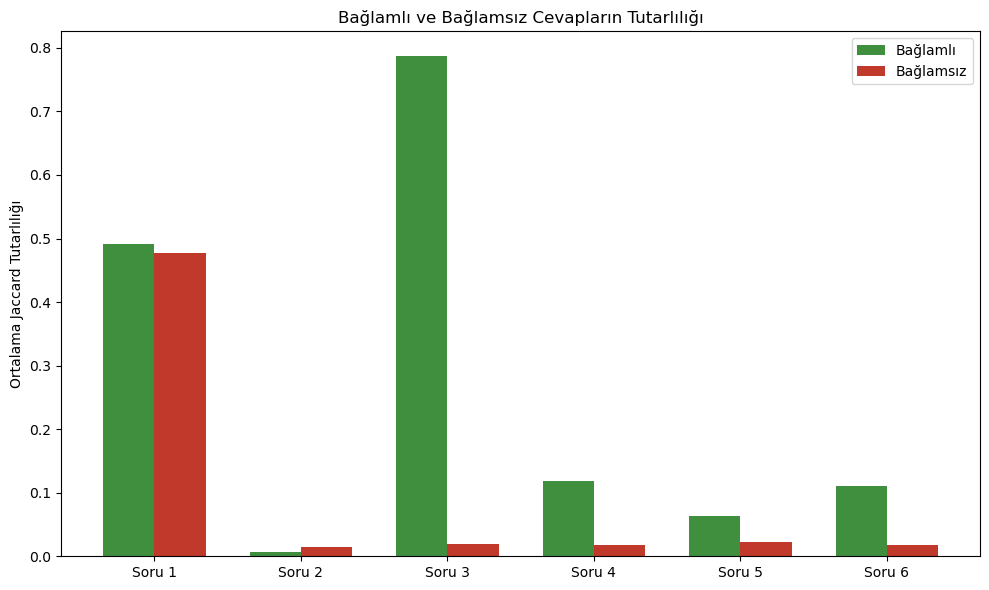

In [65]:
print("\n==== Egzersiz 5: Tutarlılık bir halüsinasyon dedektörü olabilir mi? ====")
# TODO 1: önce (c) tahminini yaz
# TODO 2: SECILEN = BILGILER[:6]   # ya da kendi seçtiğin 6 soru
# TODO 3: for (pasaj, anahtar, soru) in SECILEN: iki koşul için rag_uret(soru, pasaj_veya_None, n=6, sample=True, T=1.0, top_p=0.9)
# TODO 4: def jaccard(a, b): ka, kb = set(a.lower().split()), set(b.lower().split()); return len(ka & kb) / max(len(ka | kb), 1)
#         tutarlılık = itertools.combinations(cevaplar, 2) üzerinden jaccard ortalaması   # (import itertools)
# TODO 5: soru başına iki çubuklu grafik (bağlamlı / bağlamsız) (c)
# TODO 6: bağlamlı koşulda dogru() olan ve olmayan cevapların tutarlılığını ayrı hesapla; eşik koyup yakalama/yanlış alarm oranını yaz (d)
# TAHMİN C: Bağlamlı koşulda cevapların tutarlılığı daha yüksek olacak ve bağlamsız koşulda cevapların tutarlılığı daha düşük olacaktır. Bu nedenle, bağlamlı koşulda verilen cevapların Jaccard benzerliği daha yüksek olacak ve halüsinasyonları yakalamak için bir eşik belirlenebilir.


import itertools

SECILEN = BILGILER[:6]

oranlar = []

for idx, (pasaj, anahtar, soru) in enumerate(SECILEN):
    print(f"\nSORU {idx + 1}: {soru}")
    baglamli = rag_uret(soru, pasaj, n=6, sample=True, T=1.0, top_p=0.9)
    baglamsiz = rag_uret(soru, None, n=6, sample=True, T=1.0, top_p=0.9)
    print("  bağlamlı cevaplar:")
    for c in baglamli: print("   •", c)
    print("  bağlamsız cevaplar:")
    for c in baglamsiz: print("   •", c)

    oranlar.append(dict(baglamli=baglamli, baglamsiz=baglamsiz, anahtar=anahtar))

def jaccard(a, b):
    "Jaccard benzerliği: iki metin arasındaki ortak kelime oranı "
    "Formül = |A ∩ B| / |A ∪ B|"
    ka, kb = set(a.lower().split()), set(b.lower().split()); 
    return len(ka & kb) / max(len(ka | kb), 1)

baglamli_tutarlilik = []
baglamsiz_tutarlilik = []

for r in oranlar:
    baglamli_pairs = itertools.combinations(r['baglamli'], 2)
    baglamsiz_pairs = itertools.combinations(r['baglamsiz'], 2)
    
    baglamli_jaccard = [jaccard(a, b) for a, b in baglamli_pairs]
    baglamsiz_jaccard = [jaccard(a, b) for a, b in baglamsiz_pairs]
    
    baglamli_tutarlilik.append(np.mean(baglamli_jaccard))
    baglamsiz_tutarlilik.append(np.mean(baglamsiz_jaccard))

x = np.arange(len(SECILEN))
fig, ax = plt.subplots(figsize=(10, 6))
w = 0.35
ax.bar(x - w/2, baglamli_tutarlilik, w, label="Bağlamlı", color="#3f8f3f")
ax.bar(x + w/2, baglamsiz_tutarlilik, w, label="Bağlamsız", color="#c0392b")
ax.set_xticks(x); ax.set_xticklabels([f"Soru {i+1}" for i in range(len(SECILEN))])
ax.set_ylabel("Ortalama Jaccard Tutarlılığı")
ax.set_title("Bağlamlı ve Bağlamsız Cevapların Tutarlılığı")
ax.legend()
plt.tight_layout(); plt.savefig("tutarlilik_comparison.png", dpi=130);

# (c) için sayılar: iki koşulun ortalama tutarlılığı
print(f"Ortalama Jaccard tutarlılığı: bağlamlı {np.mean(baglamli_tutarlilik):.3f} | bağlamsız {np.mean(baglamsiz_tutarlilik):.3f}")

# TODO 6: doğru/yanlış ayrımı SORU değil CEVAP düzeyinde yapılmalı:
# her bağlamlı cevabın skoru = diğer 5 cevapla ortalama Jaccard; etiketi = dogru(cevap, anahtar)
cevap_skor = []
for r in oranlar:
    cv = r['baglamli']
    for i, c in enumerate(cv):
        diger = [jaccard(c, d) for j, d in enumerate(cv) if j != i]
        cevap_skor.append((np.mean(diger), dogru(c, r['anahtar'])))

dogru_s = np.array([s for s, d in cevap_skor if d]); yanlis_s = np.array([s for s, d in cevap_skor if not d])
print(f"\nBağlamlı koşul: {len(dogru_s)} doğru, {len(yanlis_s)} yanlış cevap")
print(f"Doğru cevapların ortalama tutarlılığı: {dogru_s.mean():.3f} | yanlış cevapların: {yanlis_s.mean():.3f}")

print("\nEşik taraması (skor < eşik ise 'halüsinasyon' de):")
print(f"{'eşik':>6} | {'yakalama (yanlışın kaçı yakalandı)':>36} | {'yanlış alarm (doğrunun kaçı elendi)':>38}")
for esik in [0.10, 0.20, 0.30, 0.40, 0.50]:
    yak = (yanlis_s < esik).mean() if len(yanlis_s) else float("nan")
    ya = (dogru_s < esik).mean() if len(dogru_s) else float("nan")
    print(f"{esik:>6.2f} | {yak:>35.0%} | {ya:>37.0%}")


## Kaynaklar

Tüm bağlantılar bu oturumda açılıp başlık/yazar bilgisi kontrol edildi.

**Decoding stratejileri**
- Holtzman, A., Buys, J., Du, L., Forbes, M., Choi, Y. (2019). *The Curious Case of Neural Text Degeneration* (top-p / nucleus sampling; beam search ve insan metninin olasılığı). [arXiv:1904.09751](https://arxiv.org/abs/1904.09751)
- Fan, A., Lewis, M., Dauphin, Y. (2018). *Hierarchical Neural Story Generation* (top-k sampling). [arXiv:1805.04833](https://arxiv.org/abs/1805.04833)
- Nguyen, M. N., Baker, A., Neo, C., Roush, A., Kirsch, A., Shwartz-Ziv, R. (2024). *Turning Up the Heat: Min-p Sampling for Creative and Coherent LLM Outputs* (min-p). [arXiv:2407.01082](https://arxiv.org/abs/2407.01082)
- Xu, J., Liu, X., Yan, J., Cai, D., Li, H., Li, J. (2022). *Learning to Break the Loop: Analyzing and Mitigating Repetitions for Neural Text Generation* (NeurIPS 2022; tekrar döngüsü ve self-reinforcement). [arXiv:2206.02369](https://arxiv.org/abs/2206.02369)
- Radford, A., Wu, J., Child, R., Luan, D., Amodei, D., Sutskever, I. (2019). *Language Models are Unsupervised Multitask Learners* (GPT-2; unicorn prompt'u). [PDF](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf)

**Pratik rehberler**
- von Platen, P. *How to generate text: using different decoding methods for language generation with Transformers* (greedy, beam, temperature, top-k, top-p; `no_repeat_ngram_size`). [Hugging Face blog](https://huggingface.co/blog/how-to-generate)
- Hugging Face Transformers dokümantasyonu: *Generation strategies*. [docs](https://huggingface.co/docs/transformers/generation_strategies)

**Tutarlılık, belirsizlik, halüsinasyon**
- Manakul, P., Liusie, A., Gales, M. J. F. (2023). *SelfCheckGPT: Zero-Resource Black-Box Hallucination Detection for Generative Large Language Models.* [arXiv:2303.08896](https://arxiv.org/abs/2303.08896)
- Atil, B., Aykent, S., Chittams, A., Fu, L., Passonneau, R. J., Radcliffe, E., Rajagopal, G. R., Sloan, A., Tudrej, T., Ture, F., Wu, Z., Xu, L., Baldwin, B. (2024). *Non-Determinism of "Deterministic" LLM Settings* (sıcaklığı/ayarları "deterministik" yapmak çıktının tekrarlanabilir olacağını garanti etmiyor). [arXiv:2408.04667](https://arxiv.org/abs/2408.04667)
- Lewis, P., et al. (2020). *Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks* (RAG; 07'den). [arXiv:2005.11401](https://arxiv.org/abs/2005.11401)